In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import math

from utils.helpers import *

# 0. Loading

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path='data/')

# 1. Profiling

## 1.1 Dimensionnality

In [3]:
N_train, D = x_train.shape
N_test, _ = x_test.shape

print(
    f"Train set shape:{N_train} samples and {D} features"
)
print(
    f"Test set shape:{N_test} samples and {D} features"
)
print(f"Target labels shape:    {y_train.shape}")

# Class balance check
unique_labels, counts = np.unique(y_train, return_counts=True)
print("\nClass Balance (y_train):")
for label, count in zip(unique_labels, counts):
    print(f"  Class {label:>2}: {count:>7,d} ({count / N_train * 100:.2f}%)")

Train set shape:328135 samples and 321 features
Test set shape:109379 samples and 321 features
Target labels shape:    (328135,)

Class Balance (y_train):
  Class -1: 299,160 (91.17%)
  Class  1:  28,975 (8.83%)


## 1.2 Distribution

Generating density plots for 321 features across 21 page(s)...


/tmp/ipykernel_114928/1190665273.py:20: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(GRID_ROWS, GRID_COLS, figsize=(16, 12))


Saved: figures/feature_densities_page_21.png


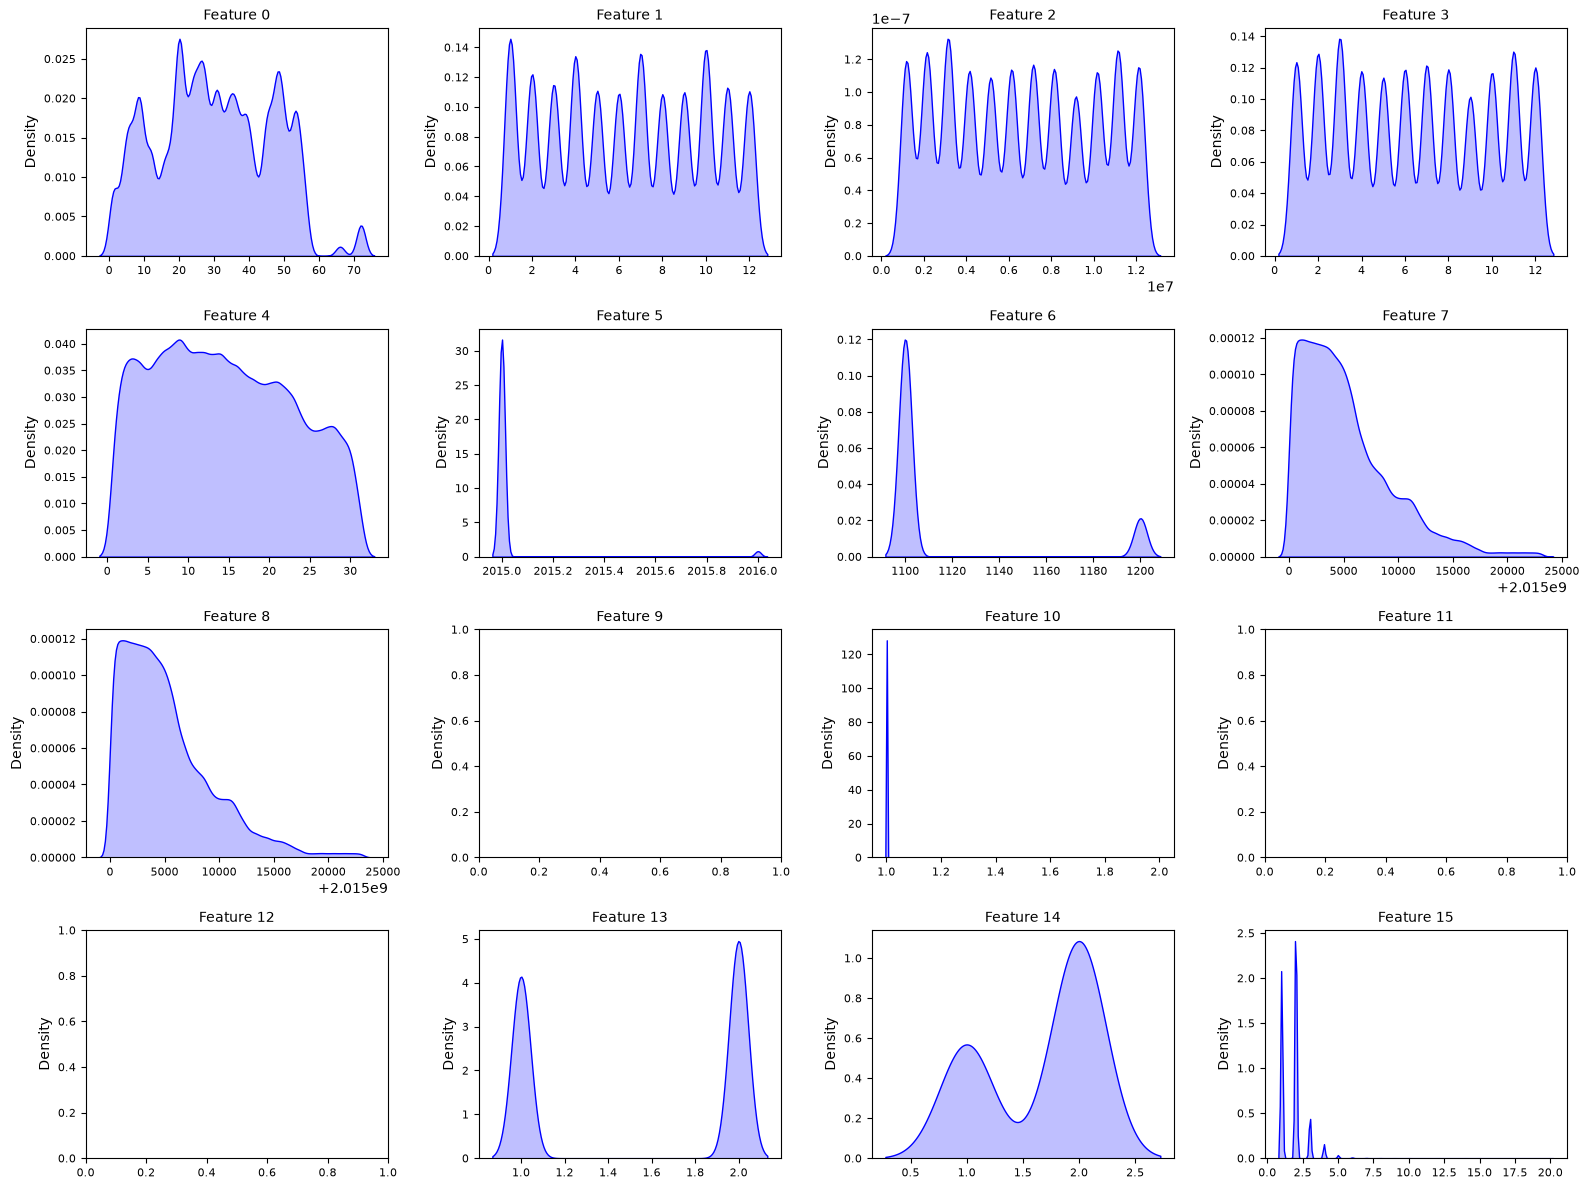

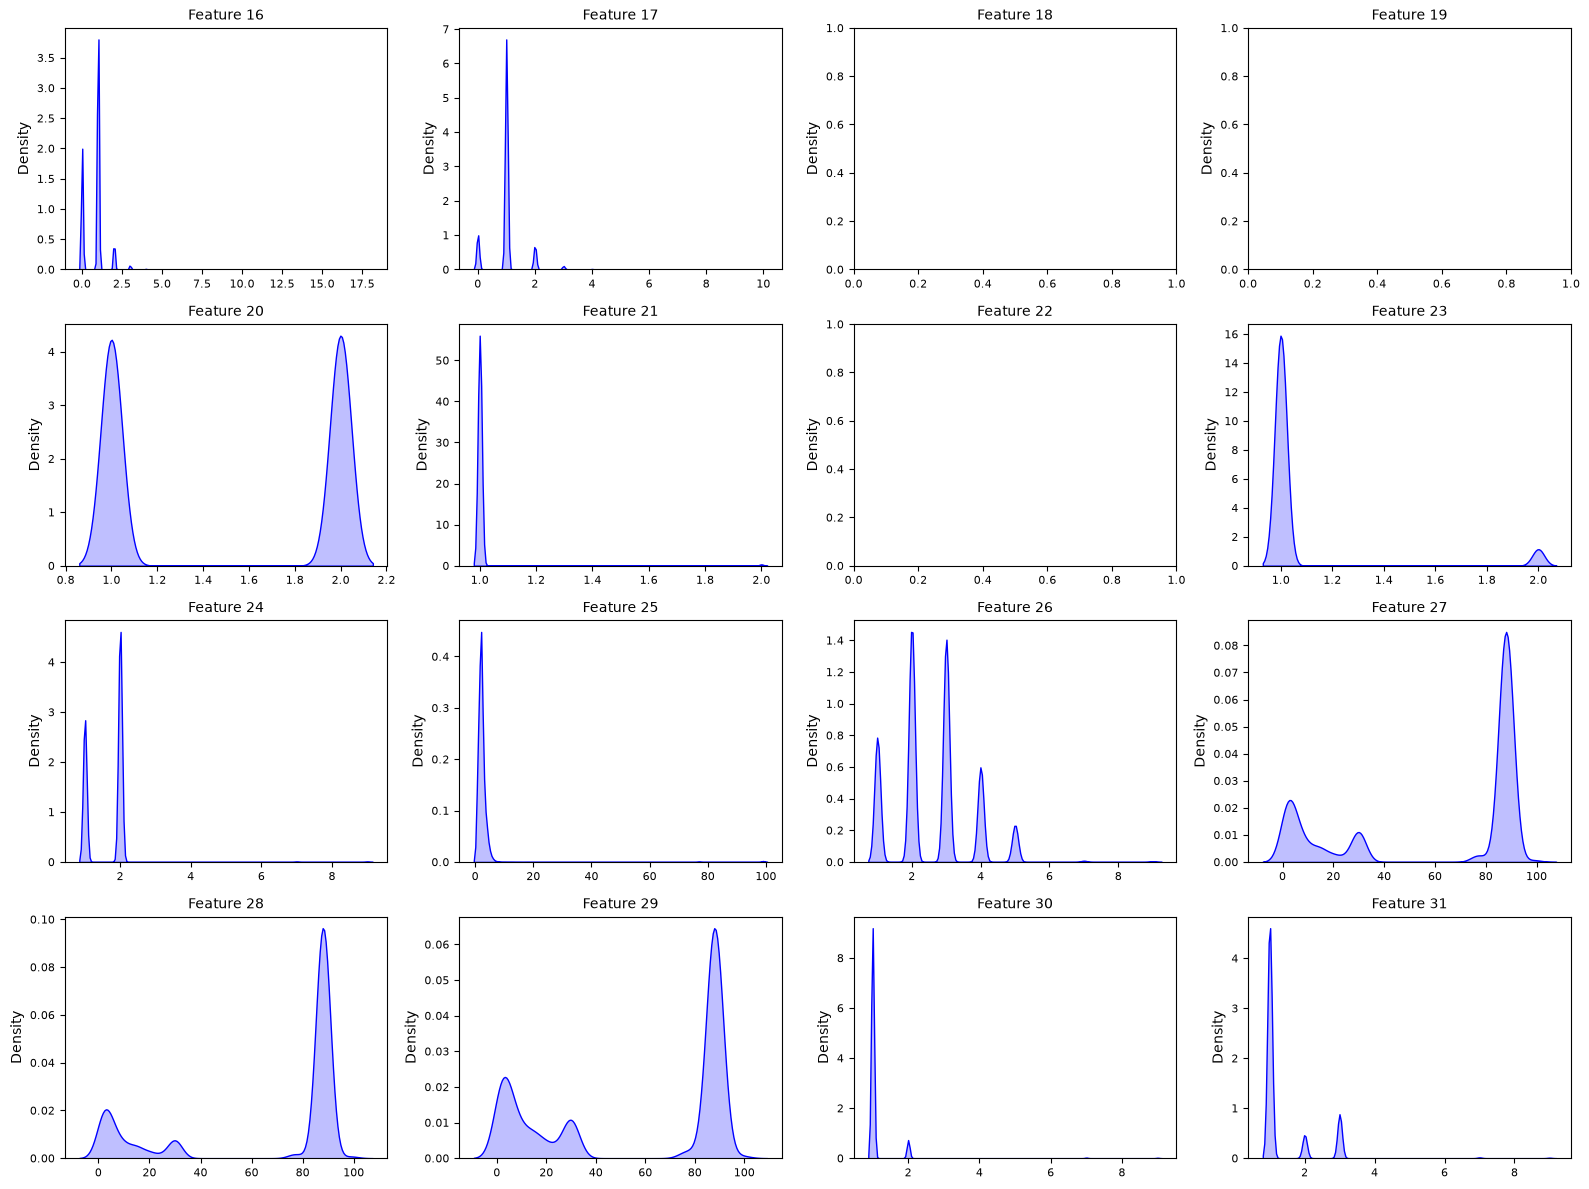

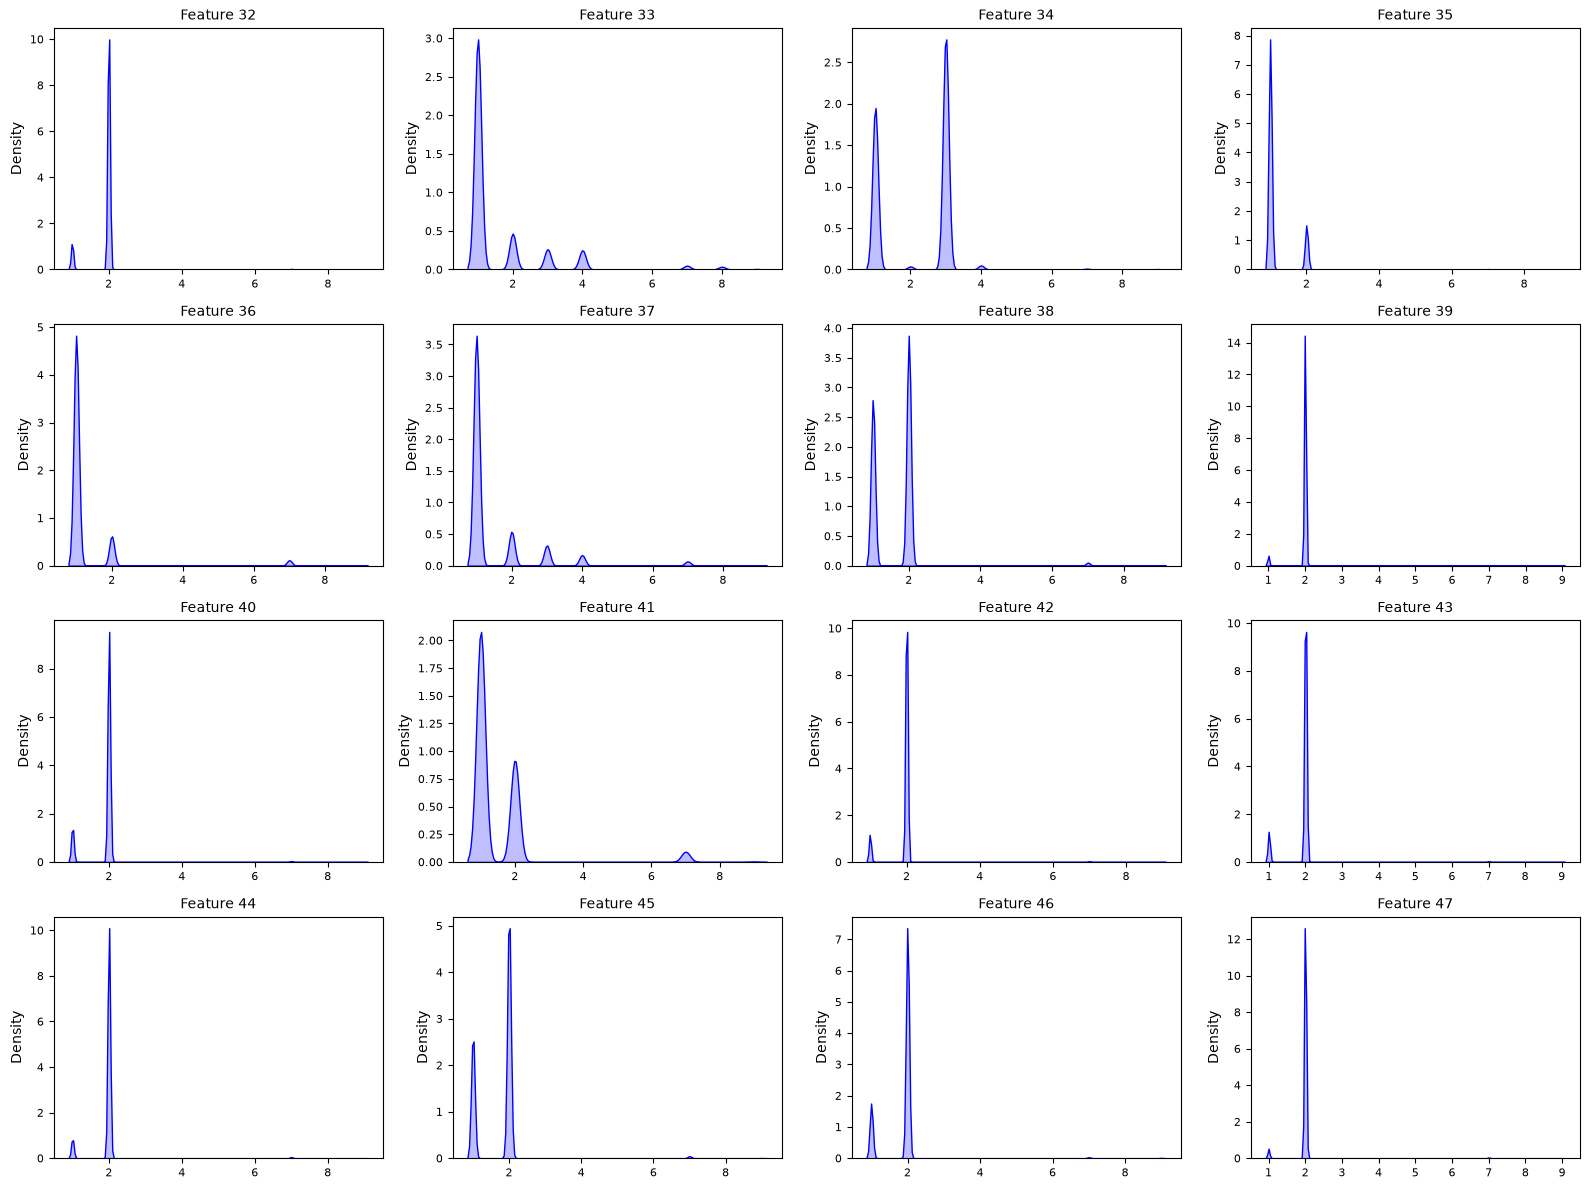

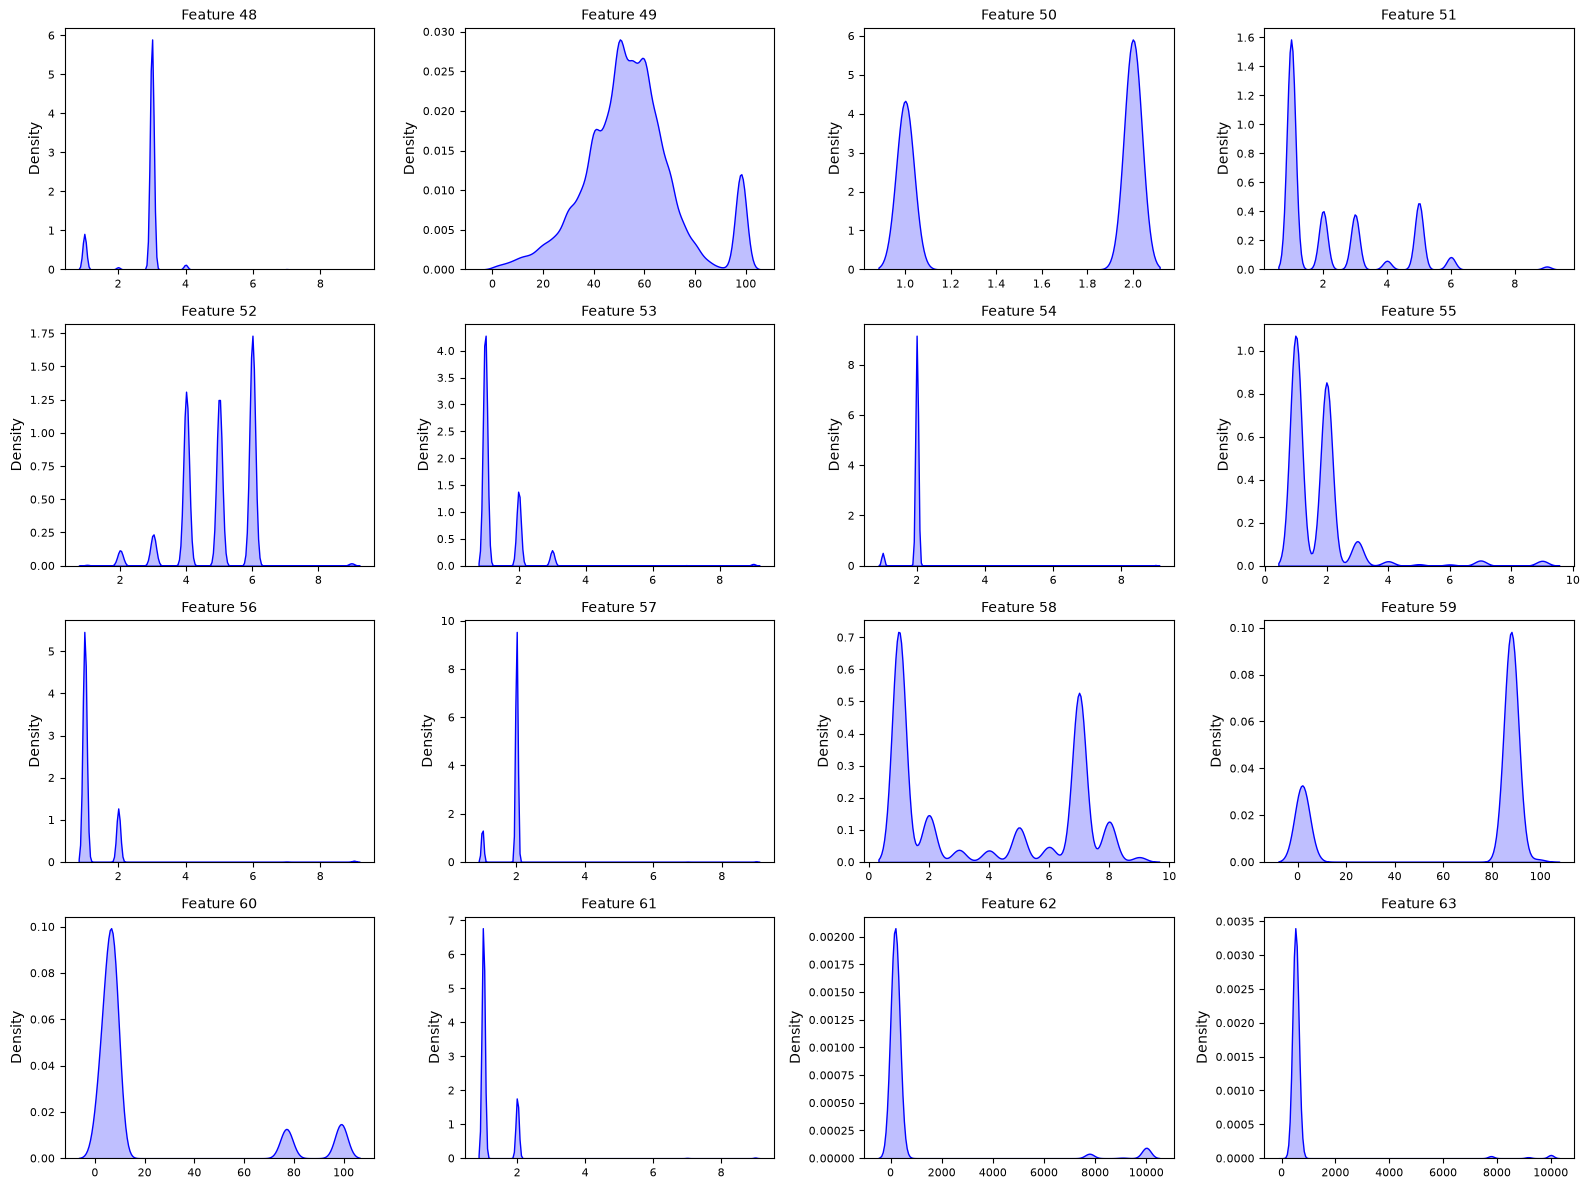

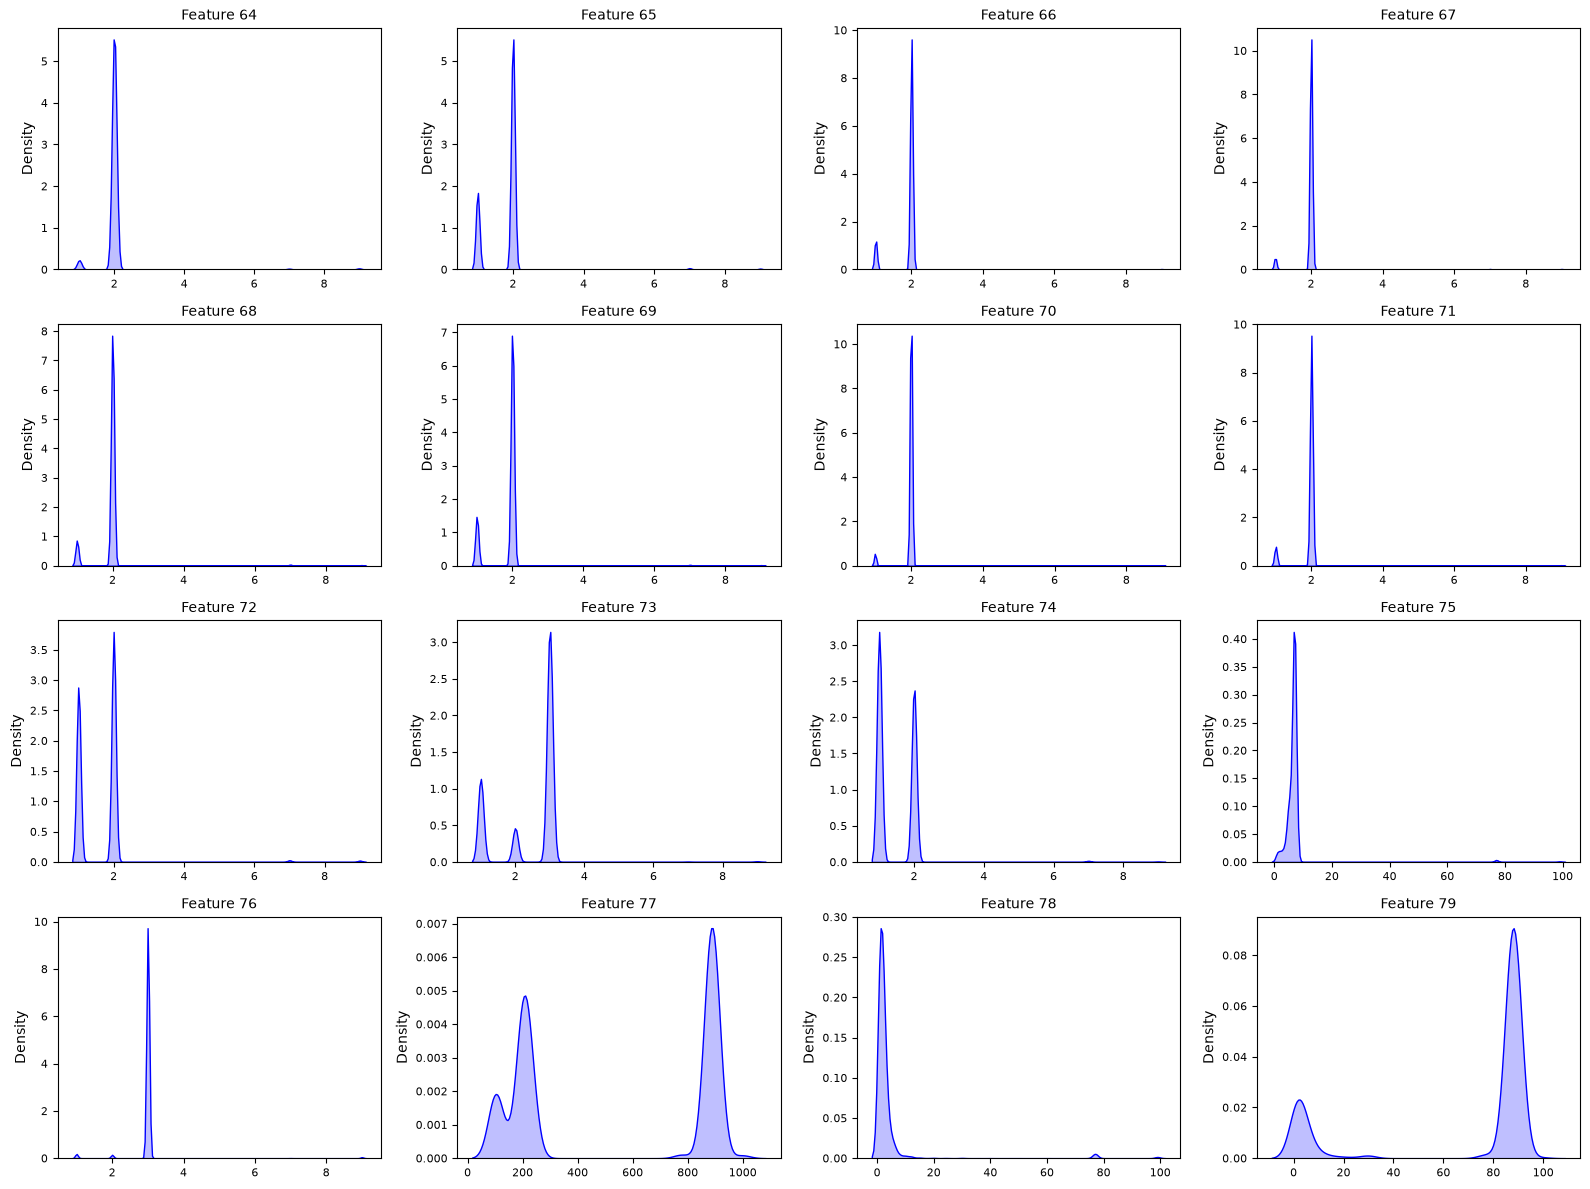

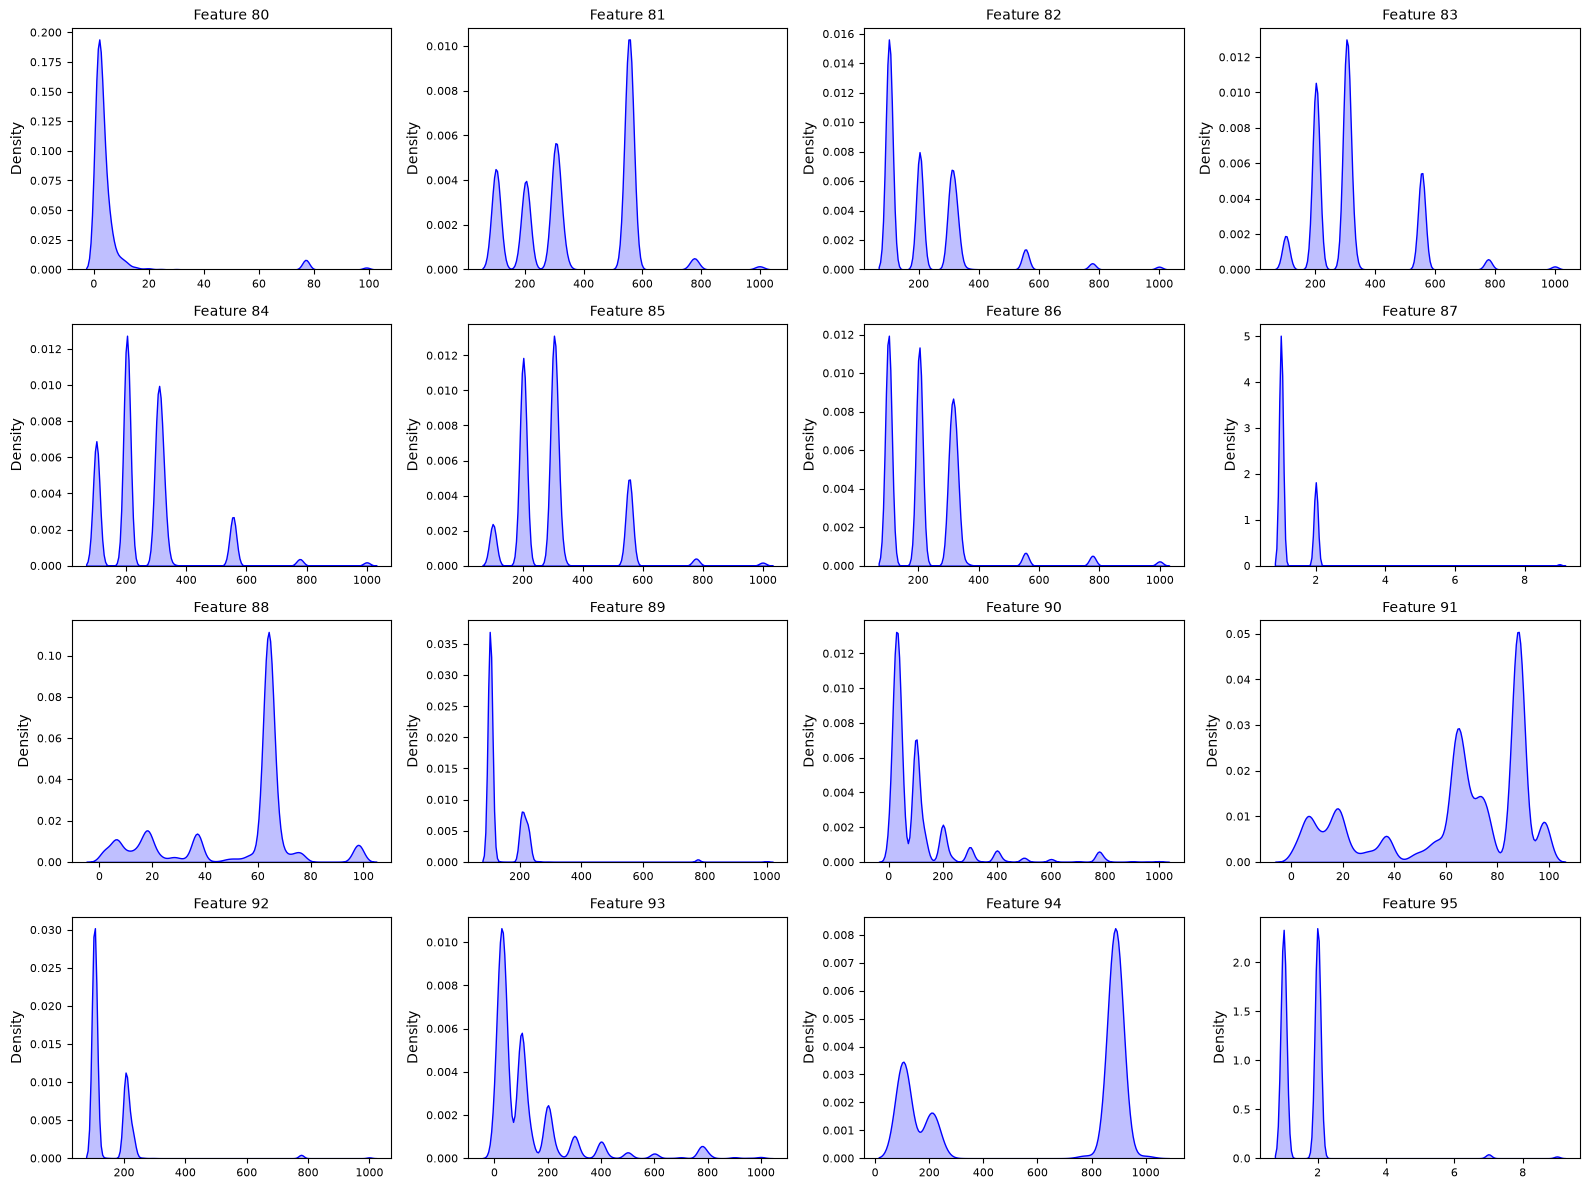

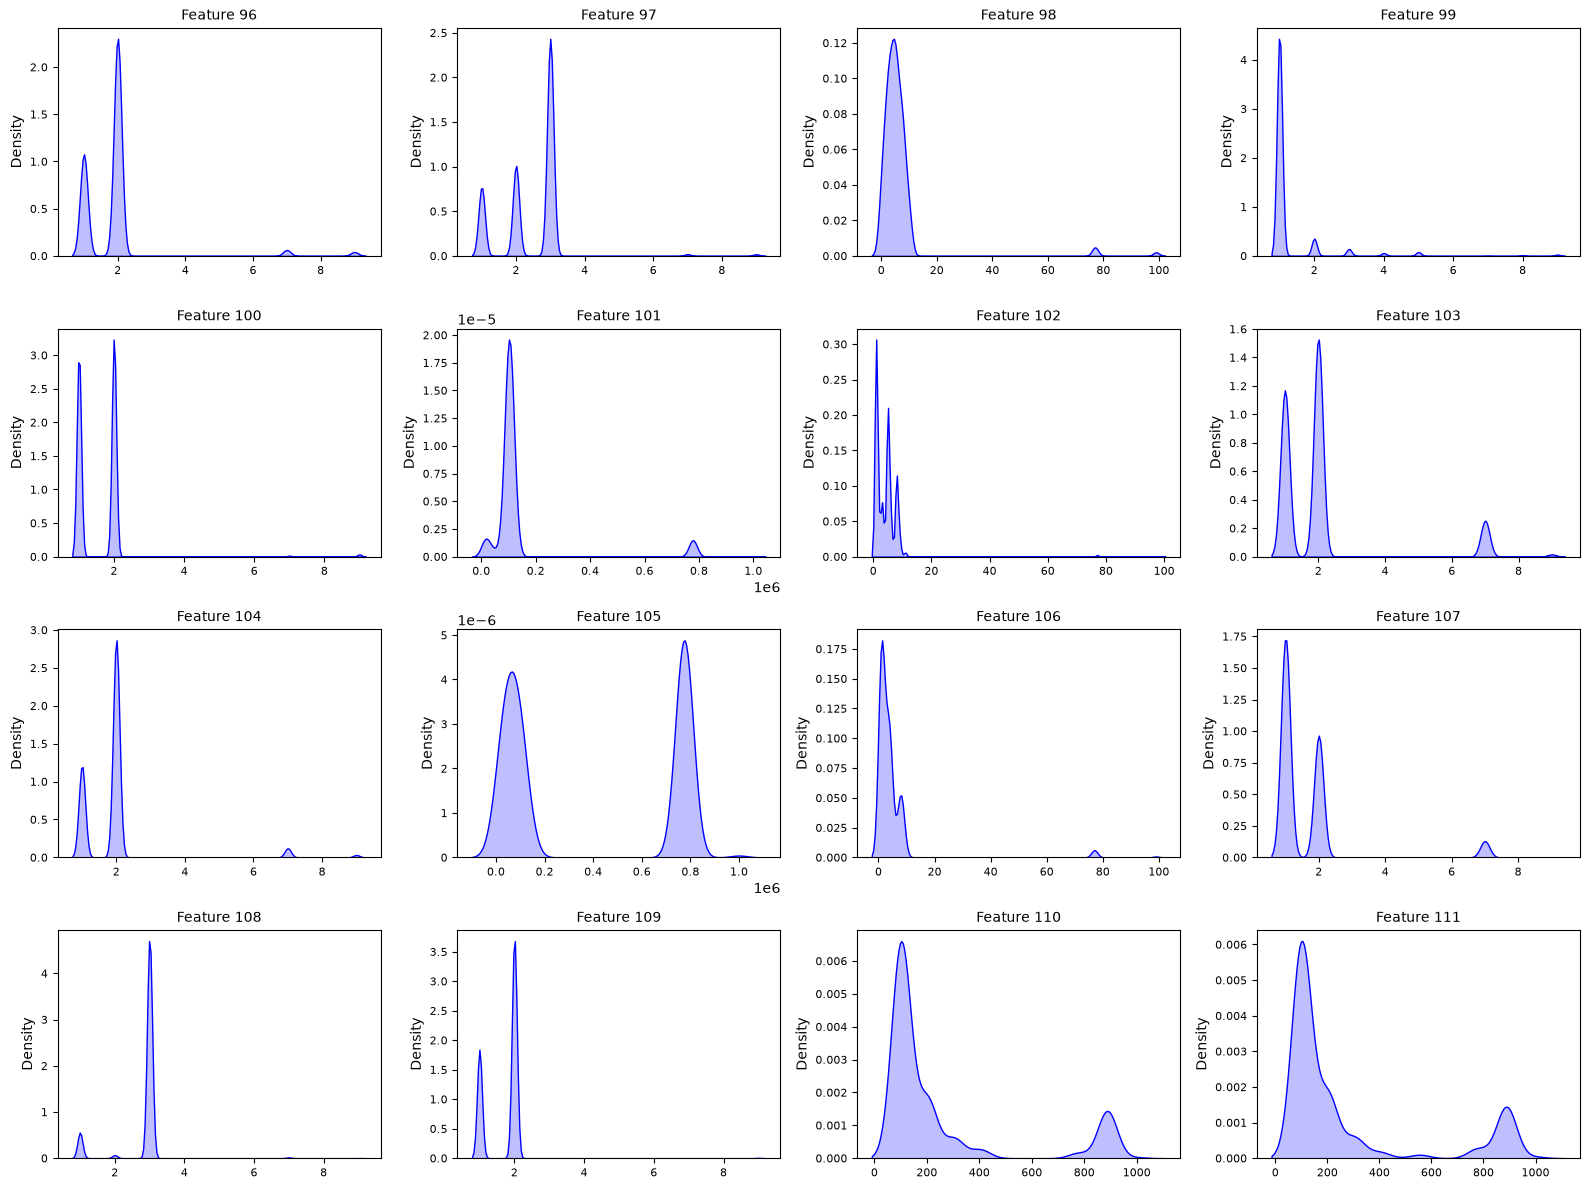

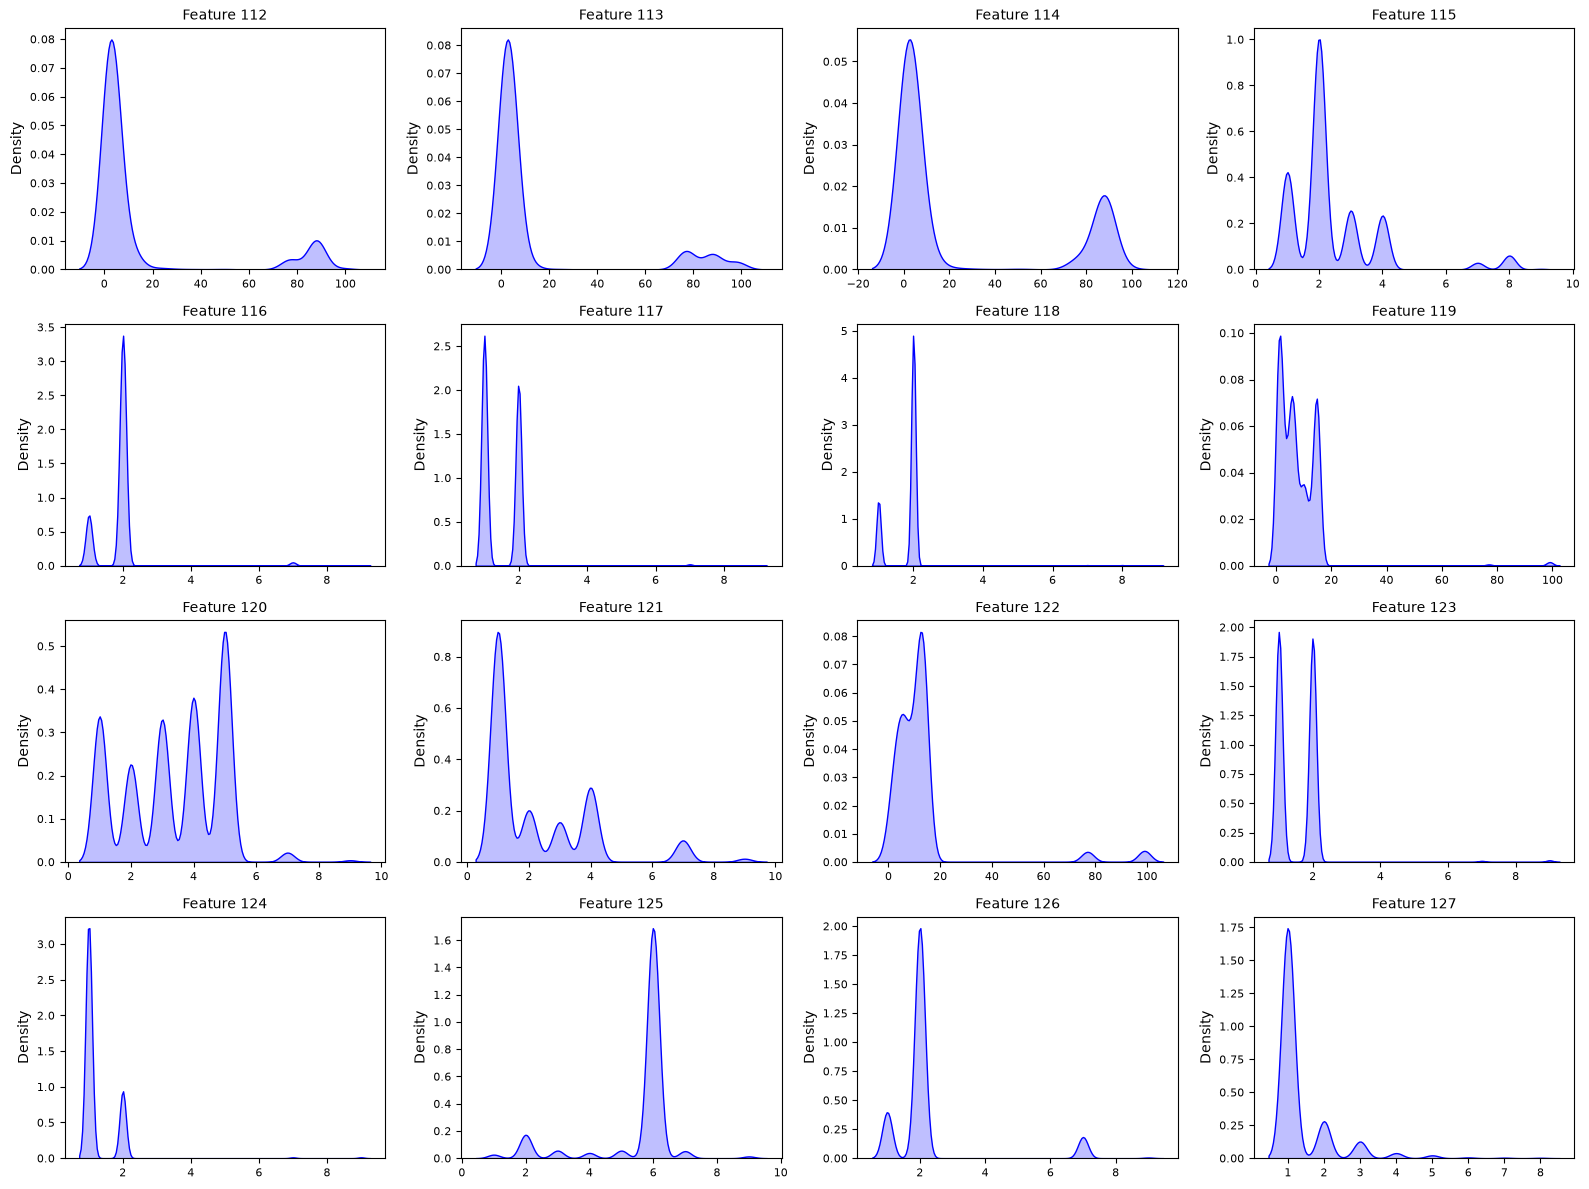

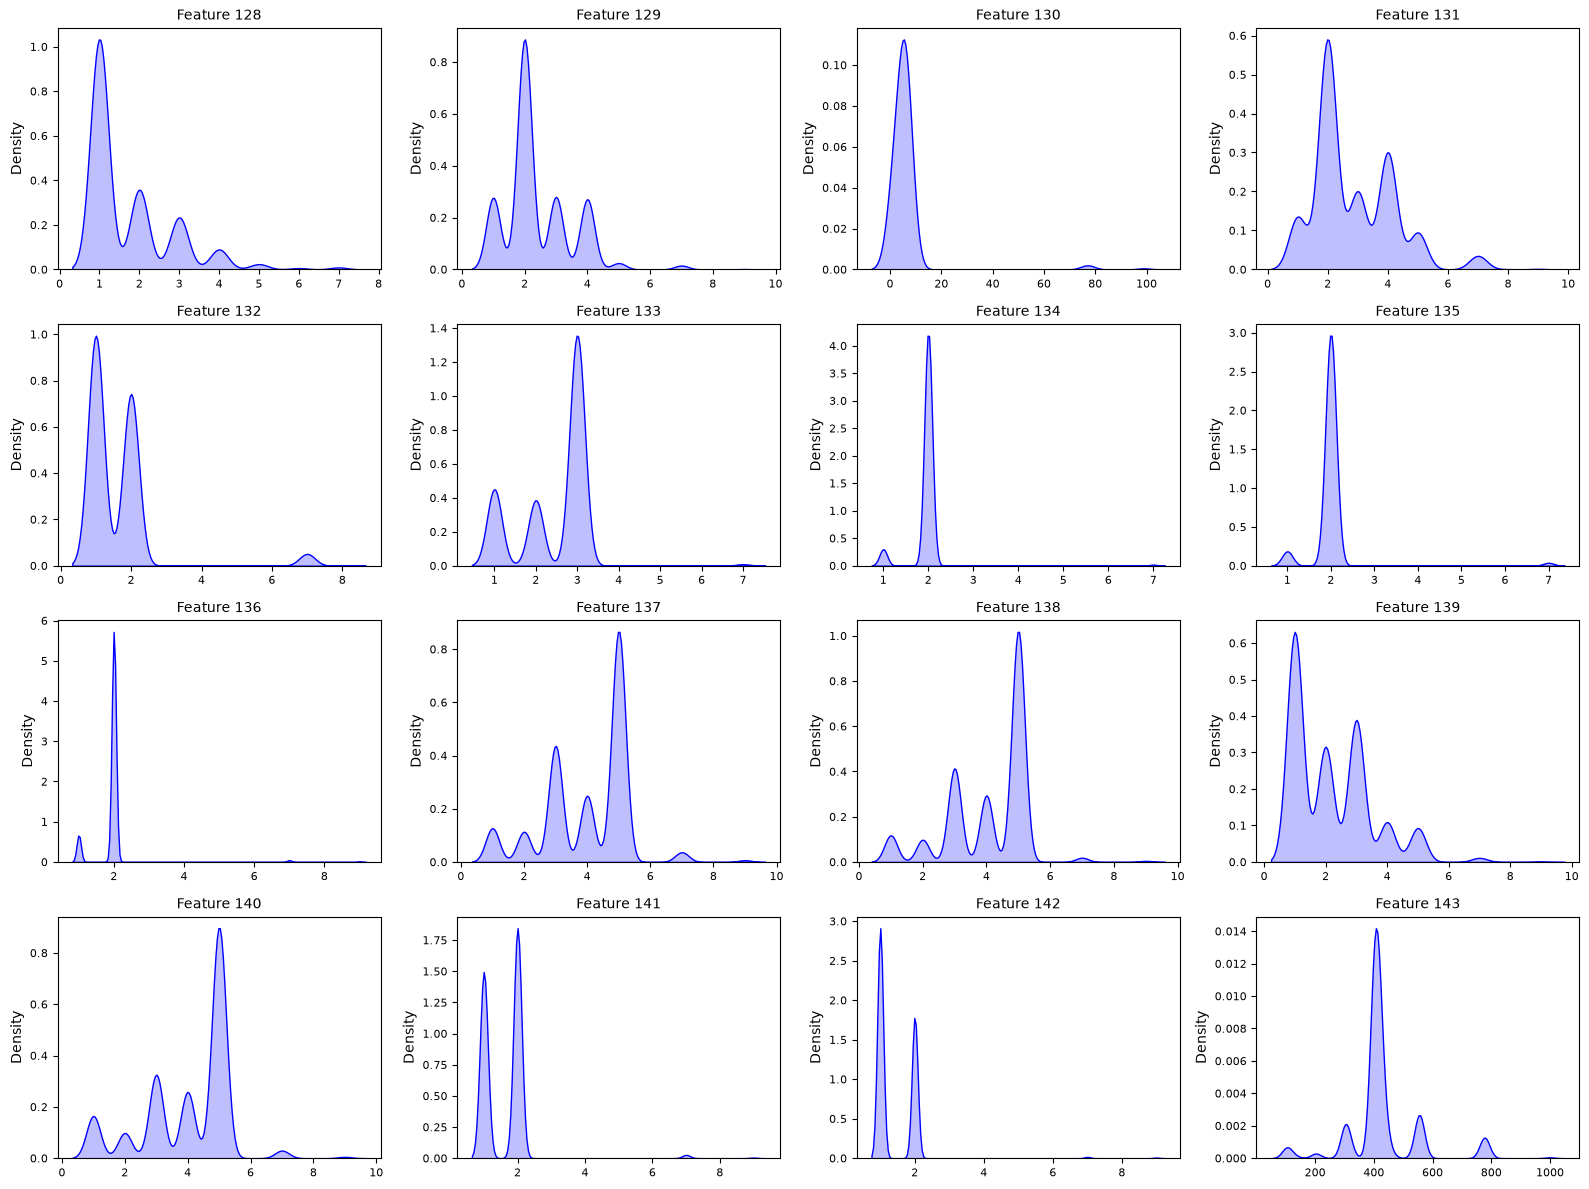

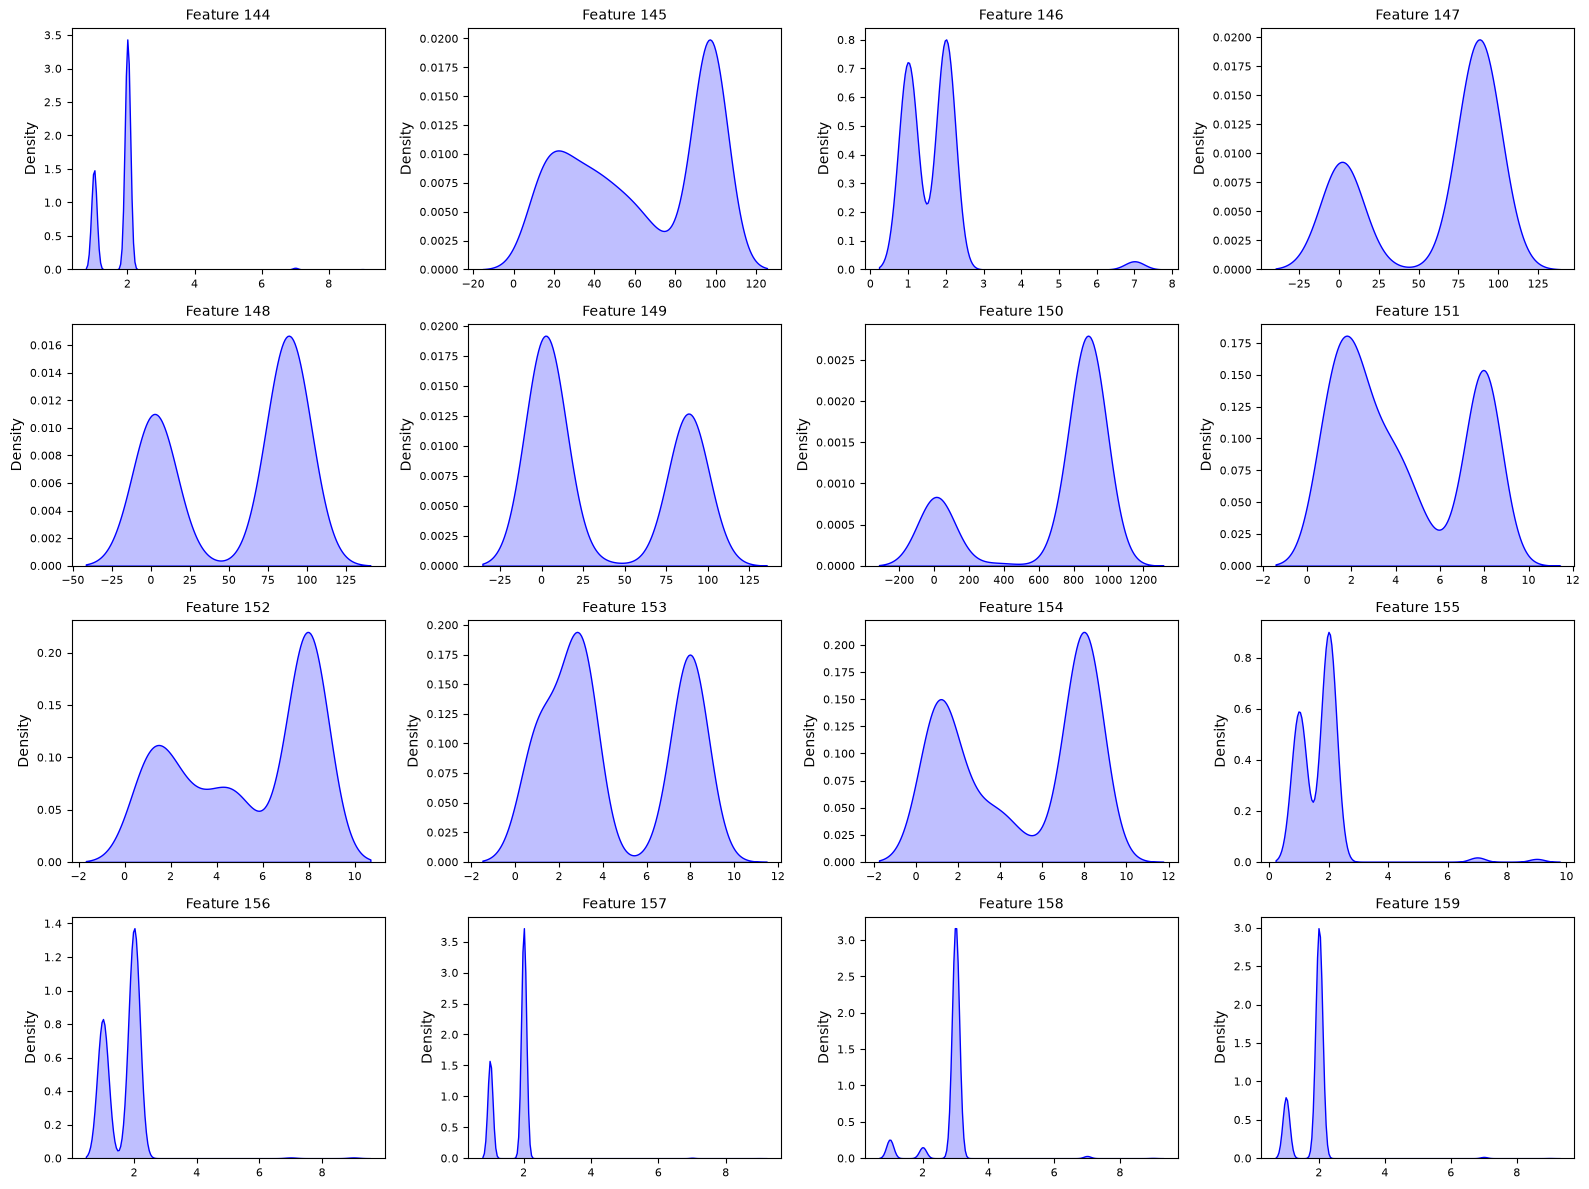

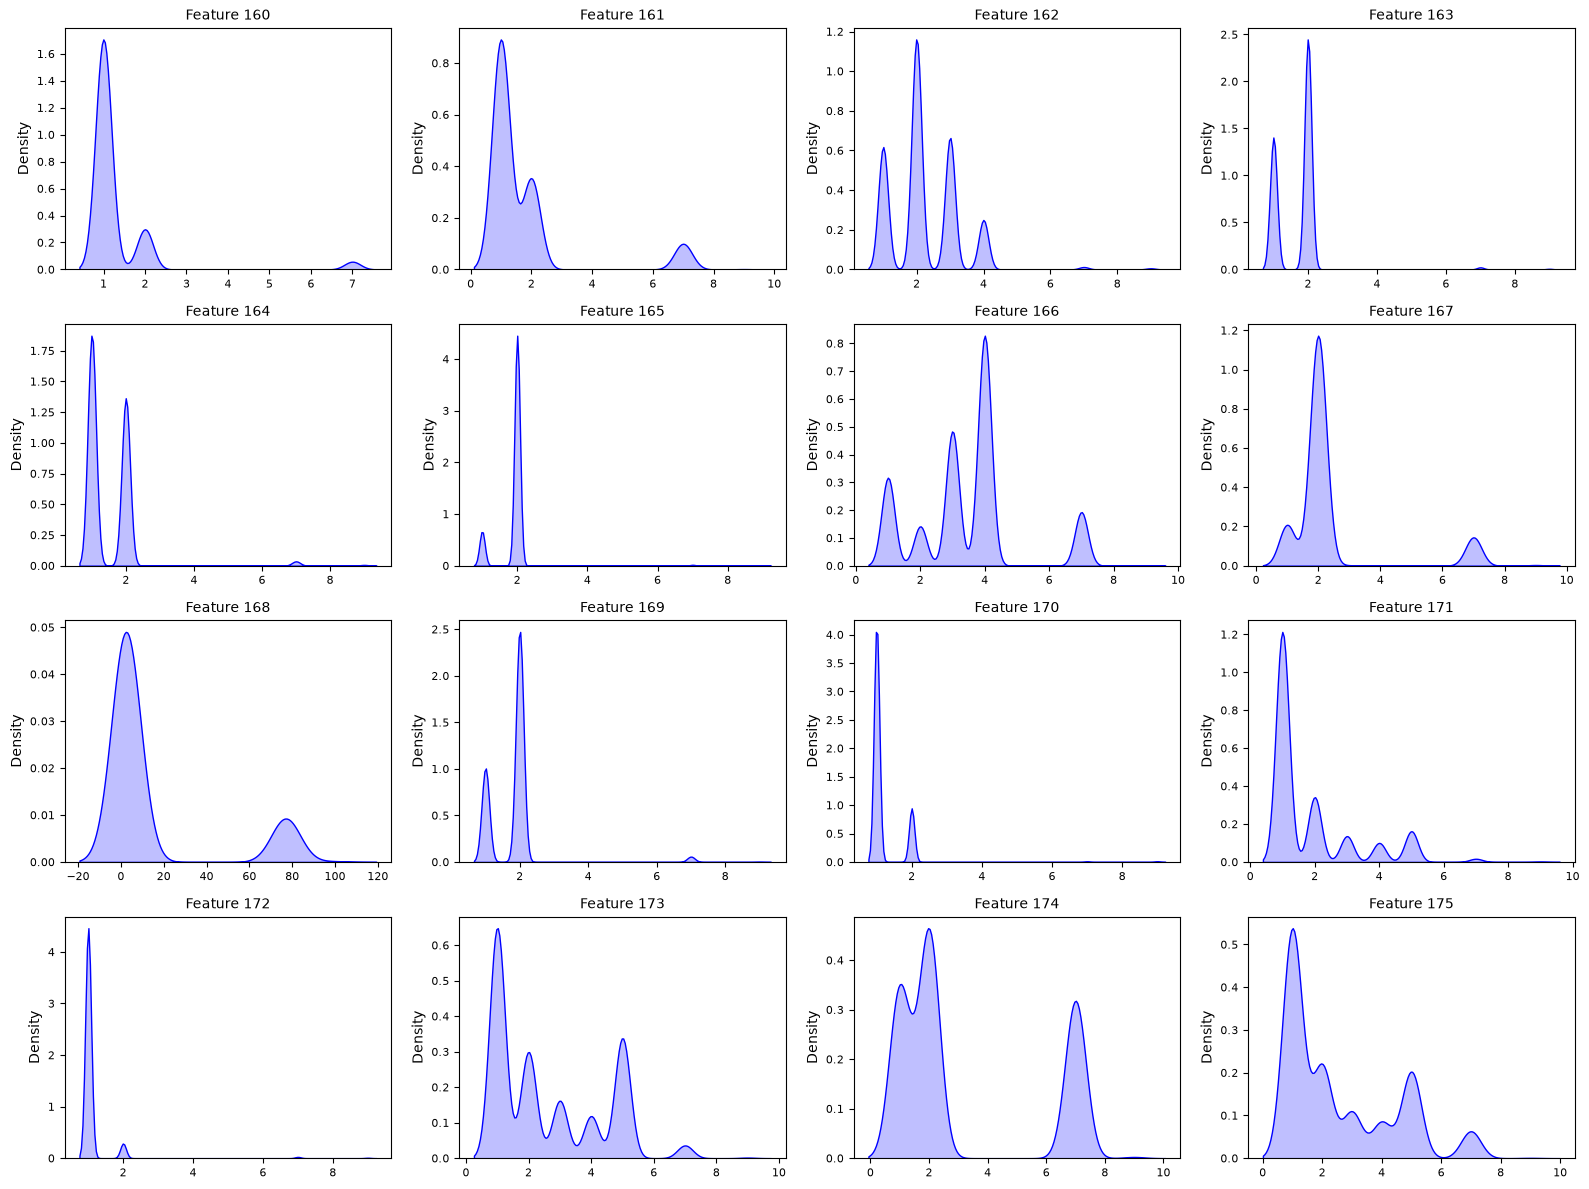

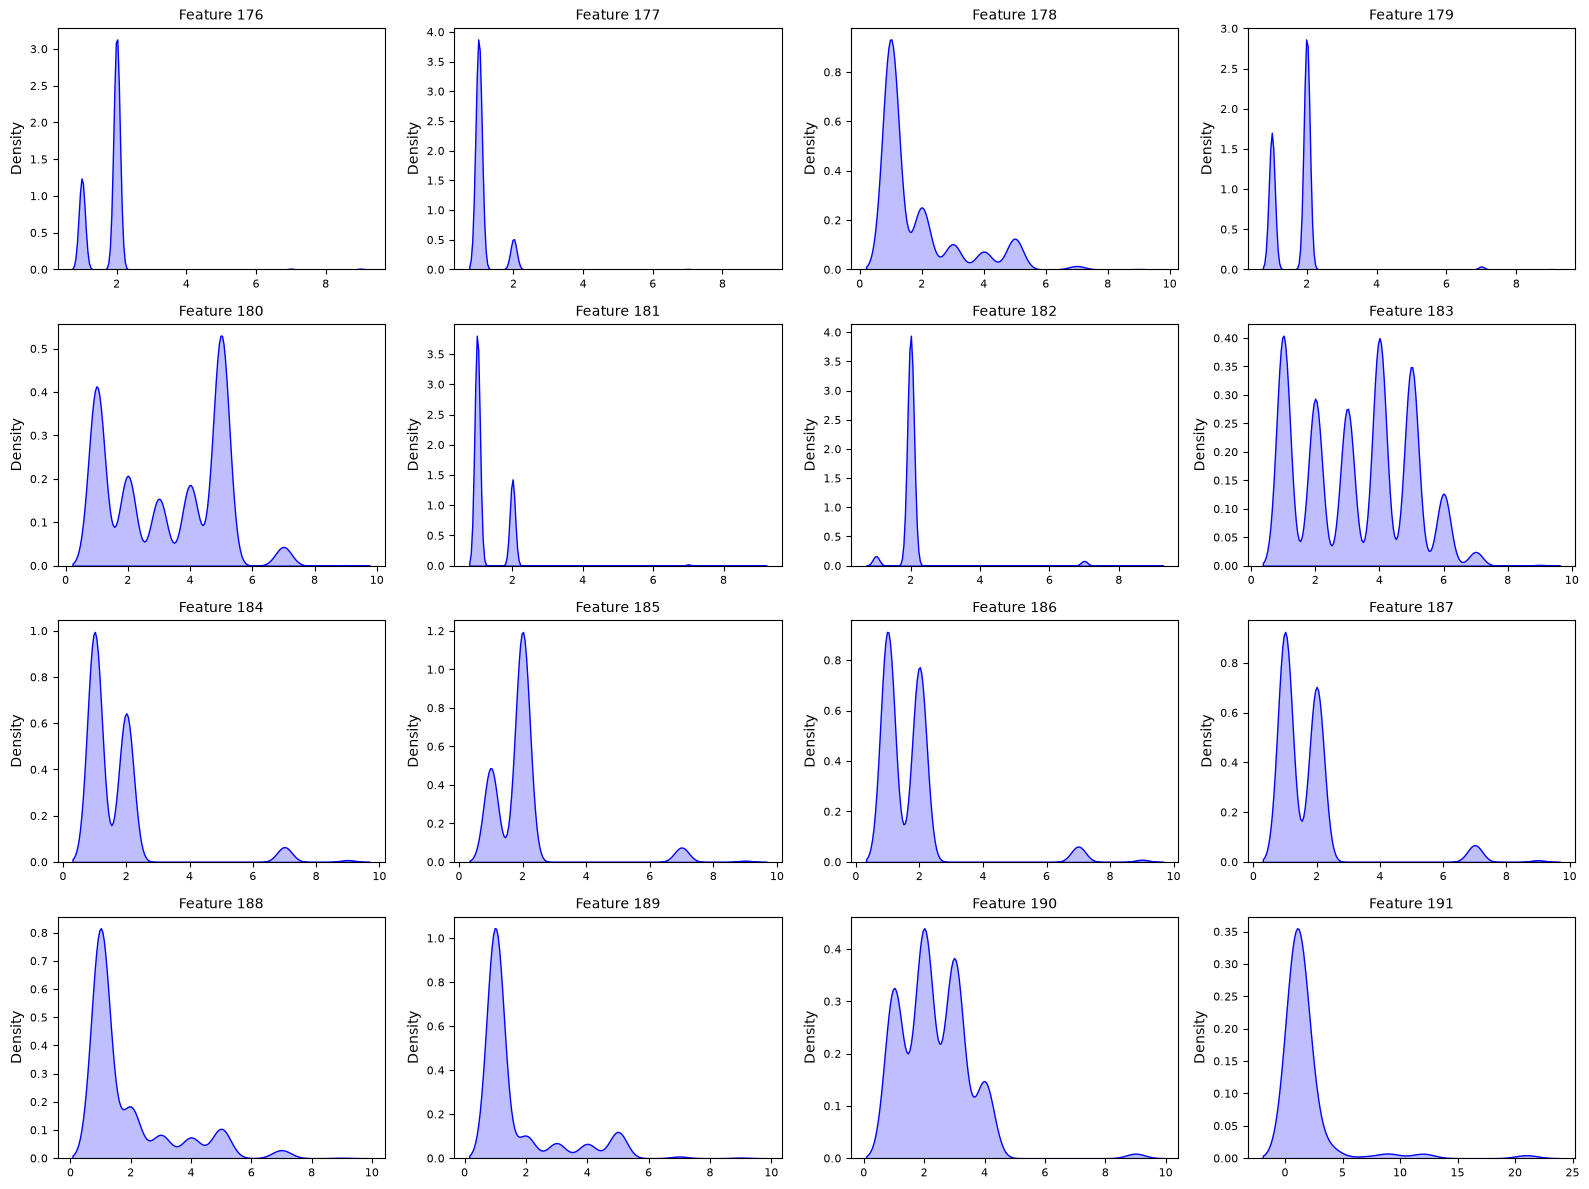

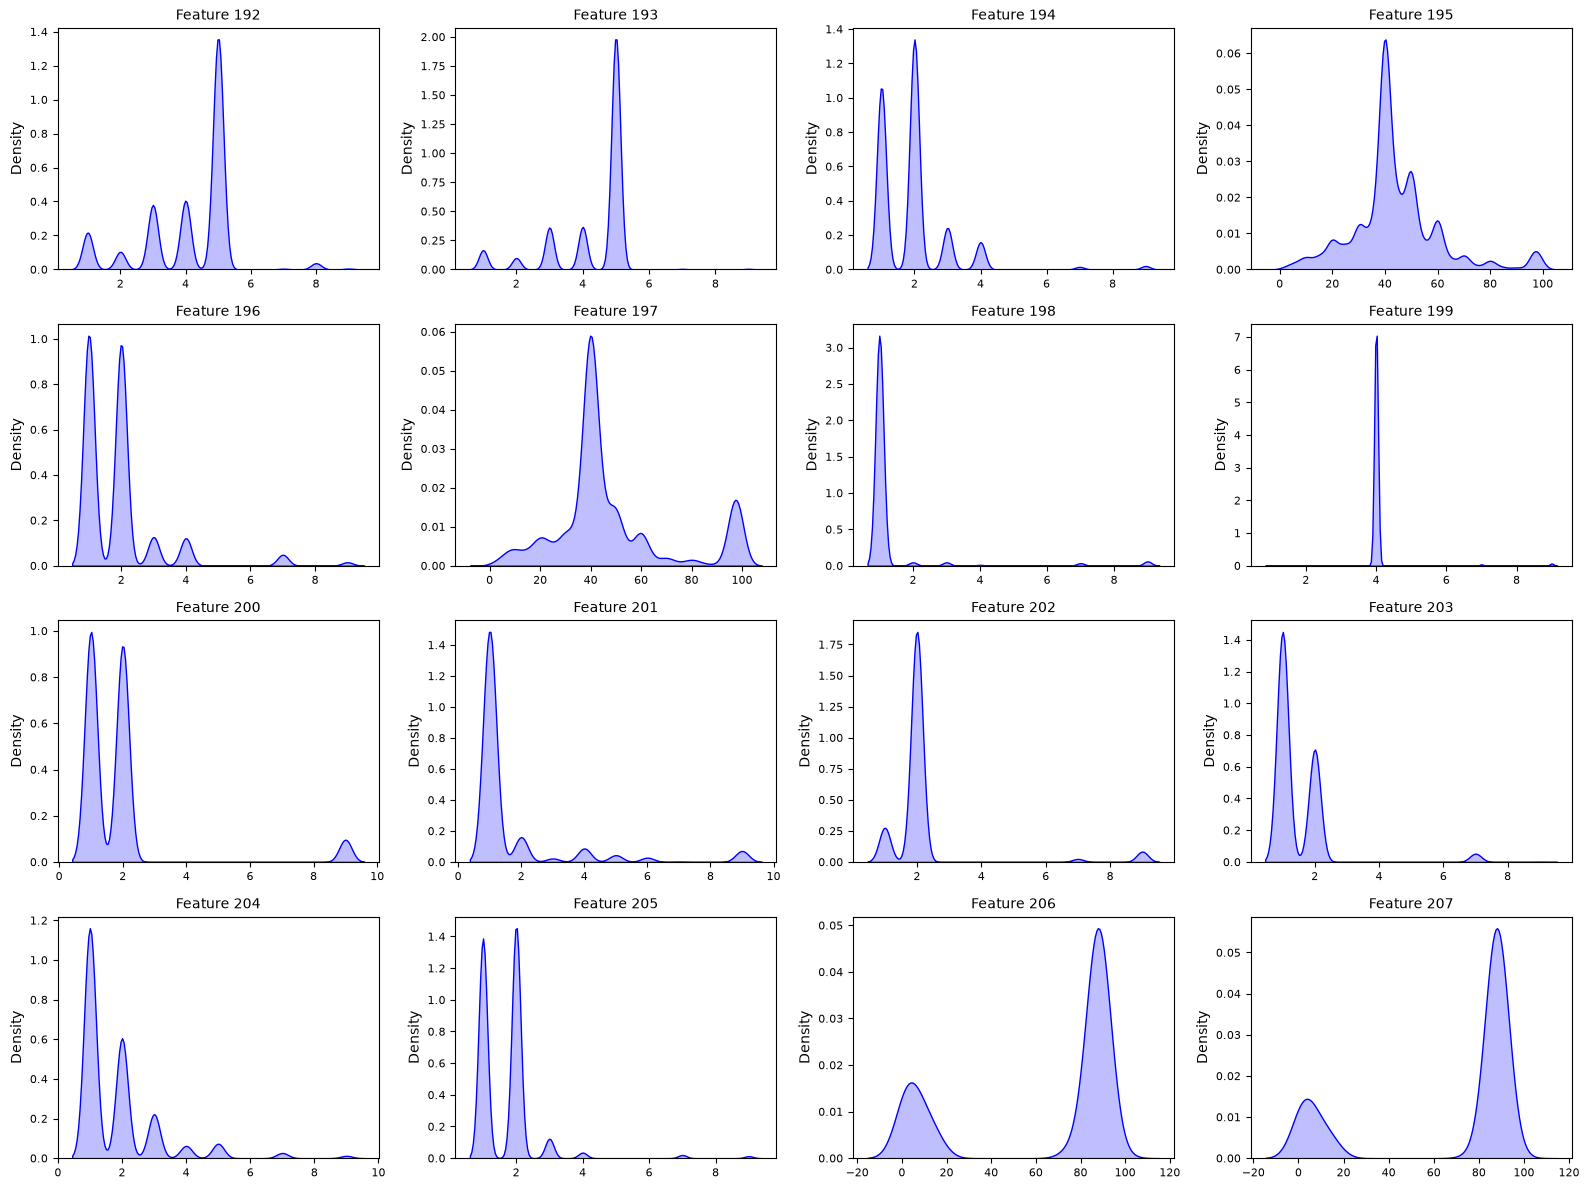

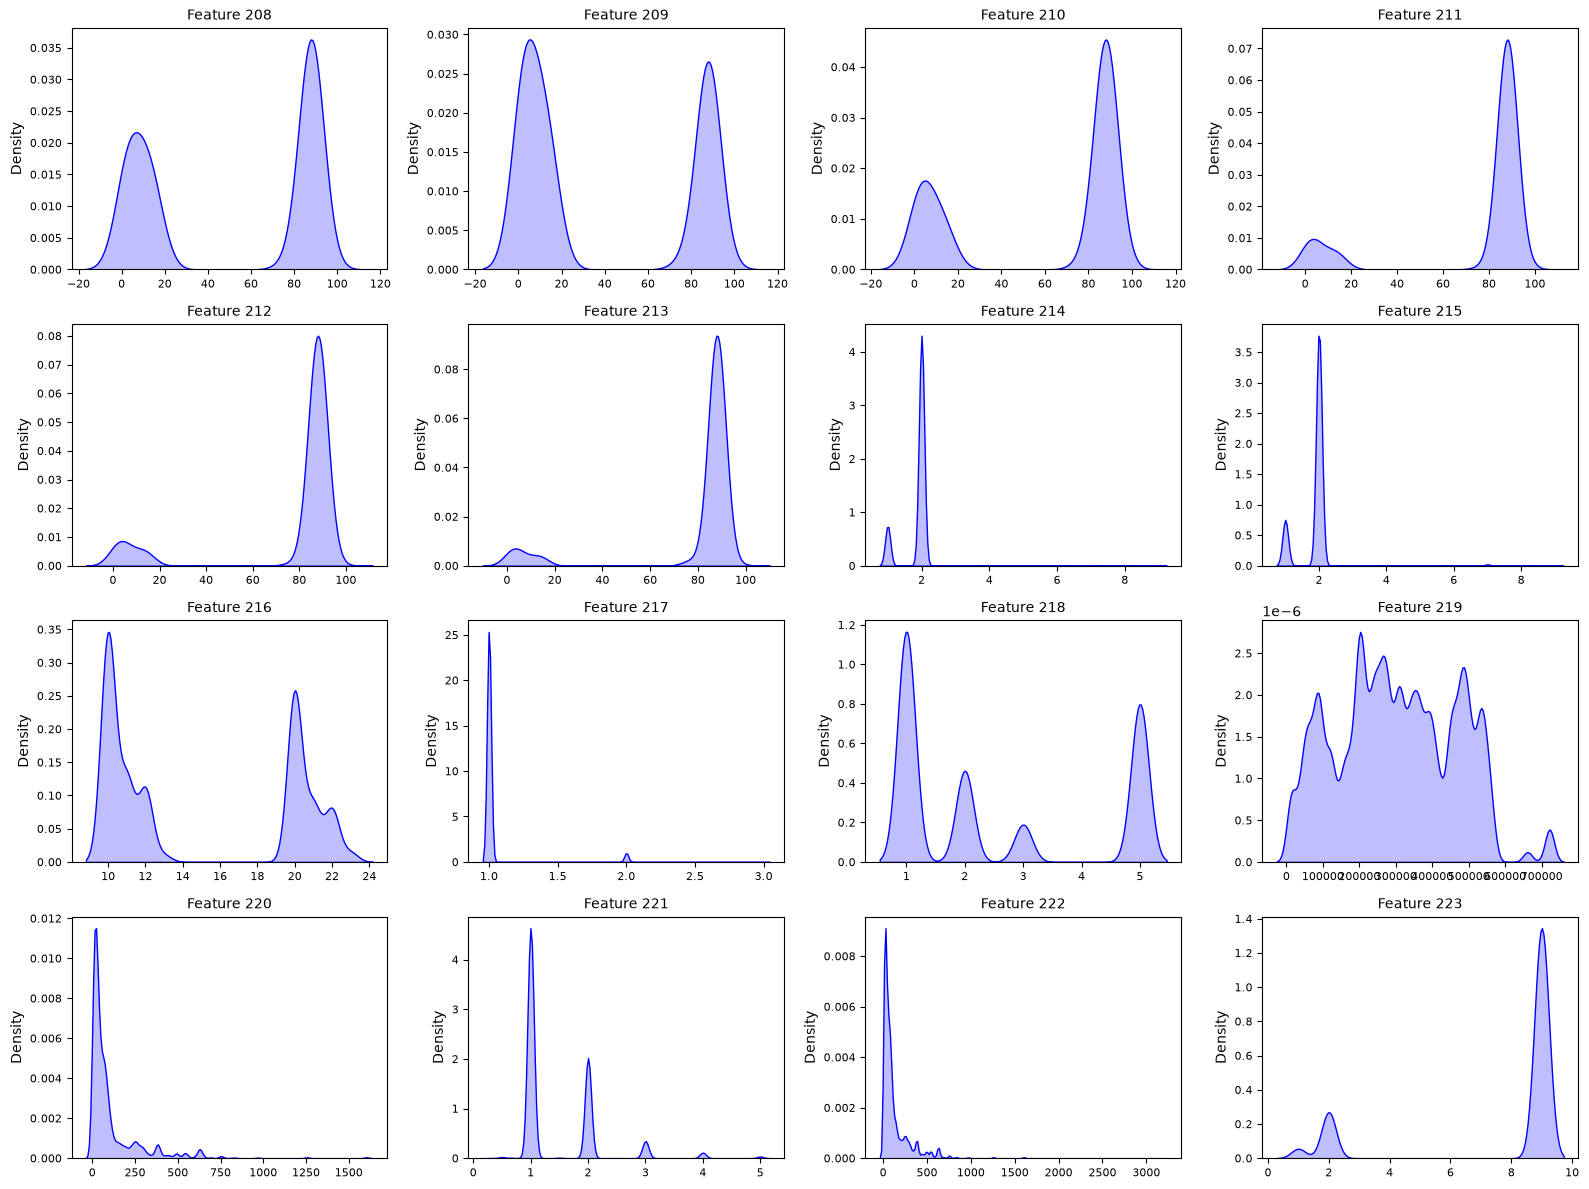

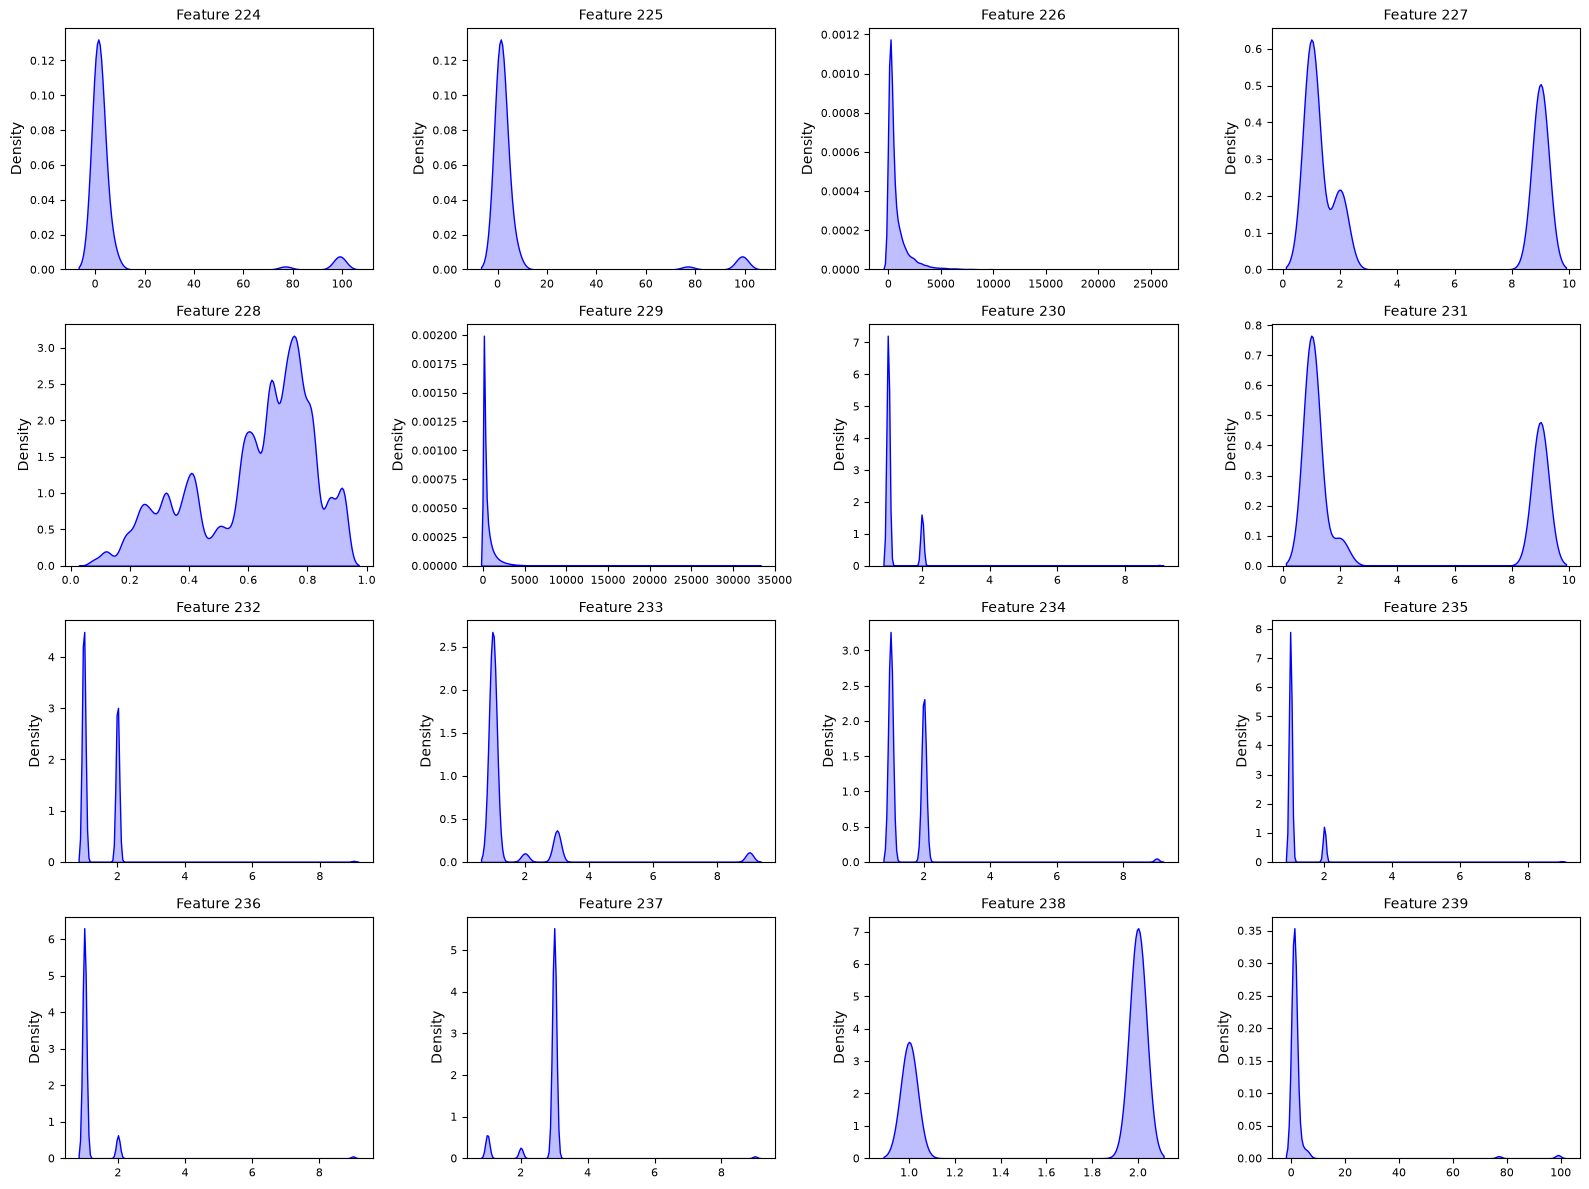

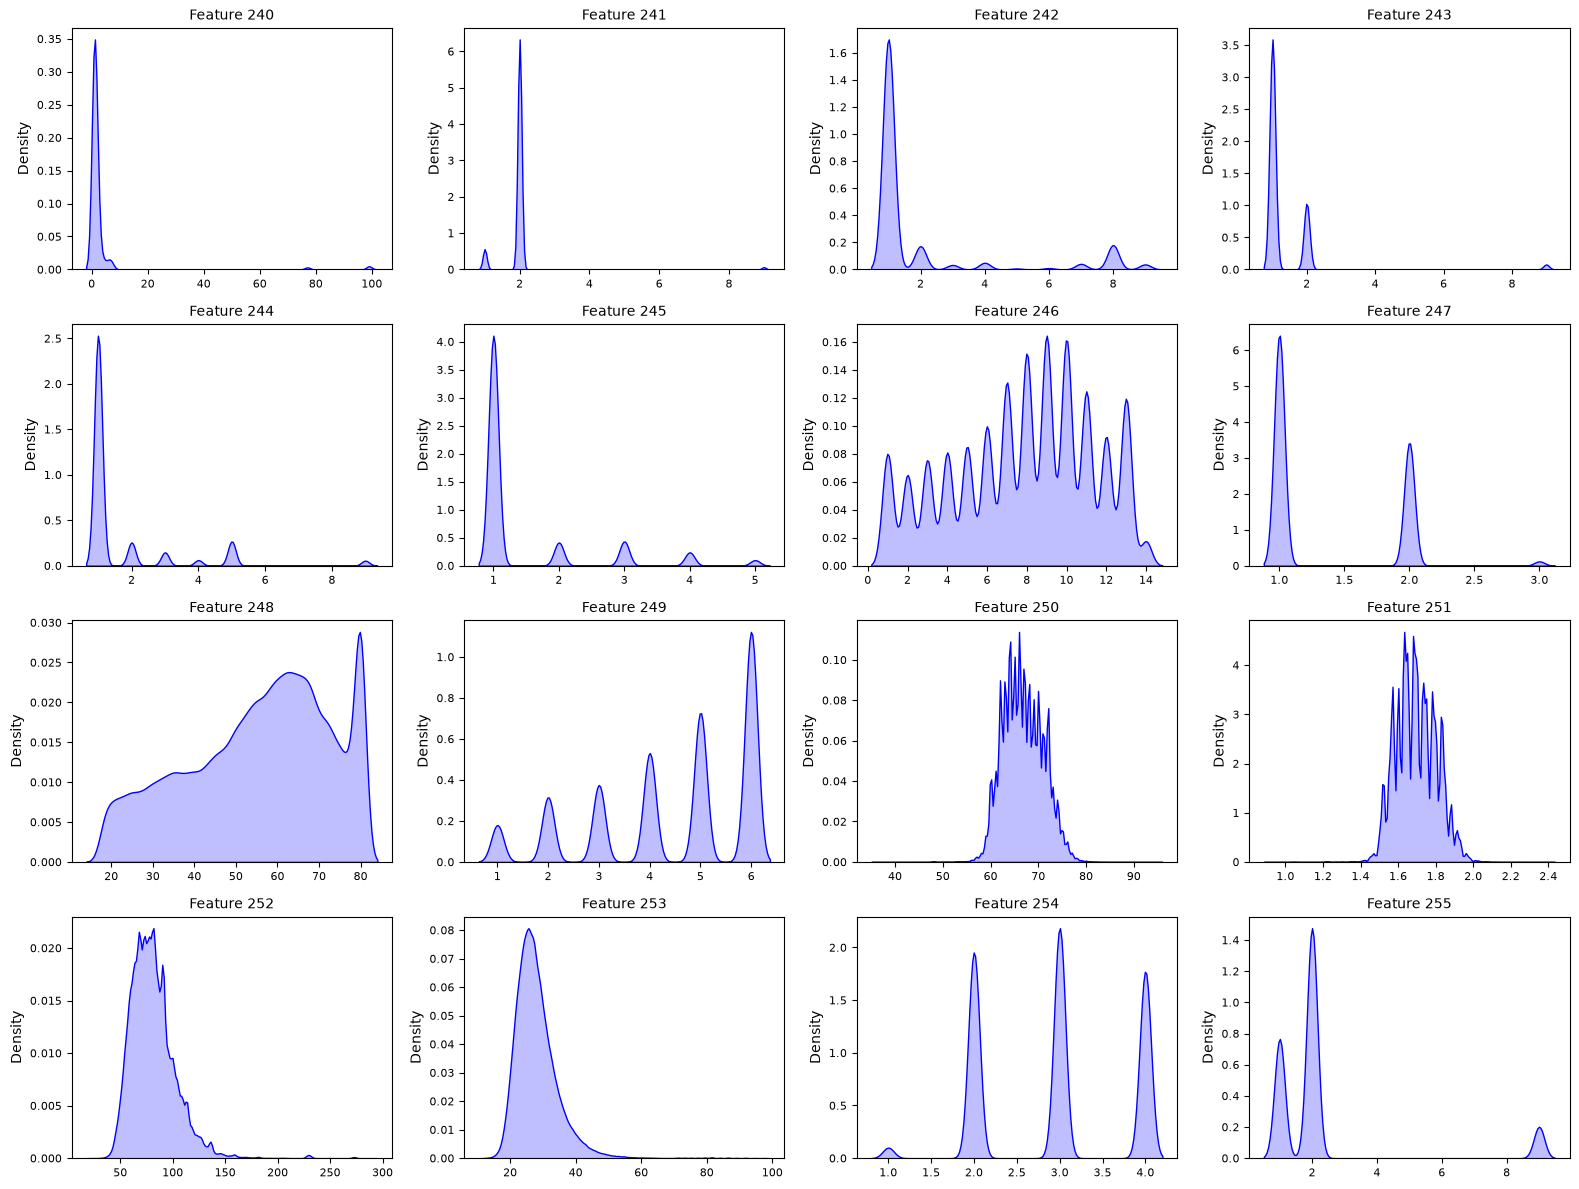

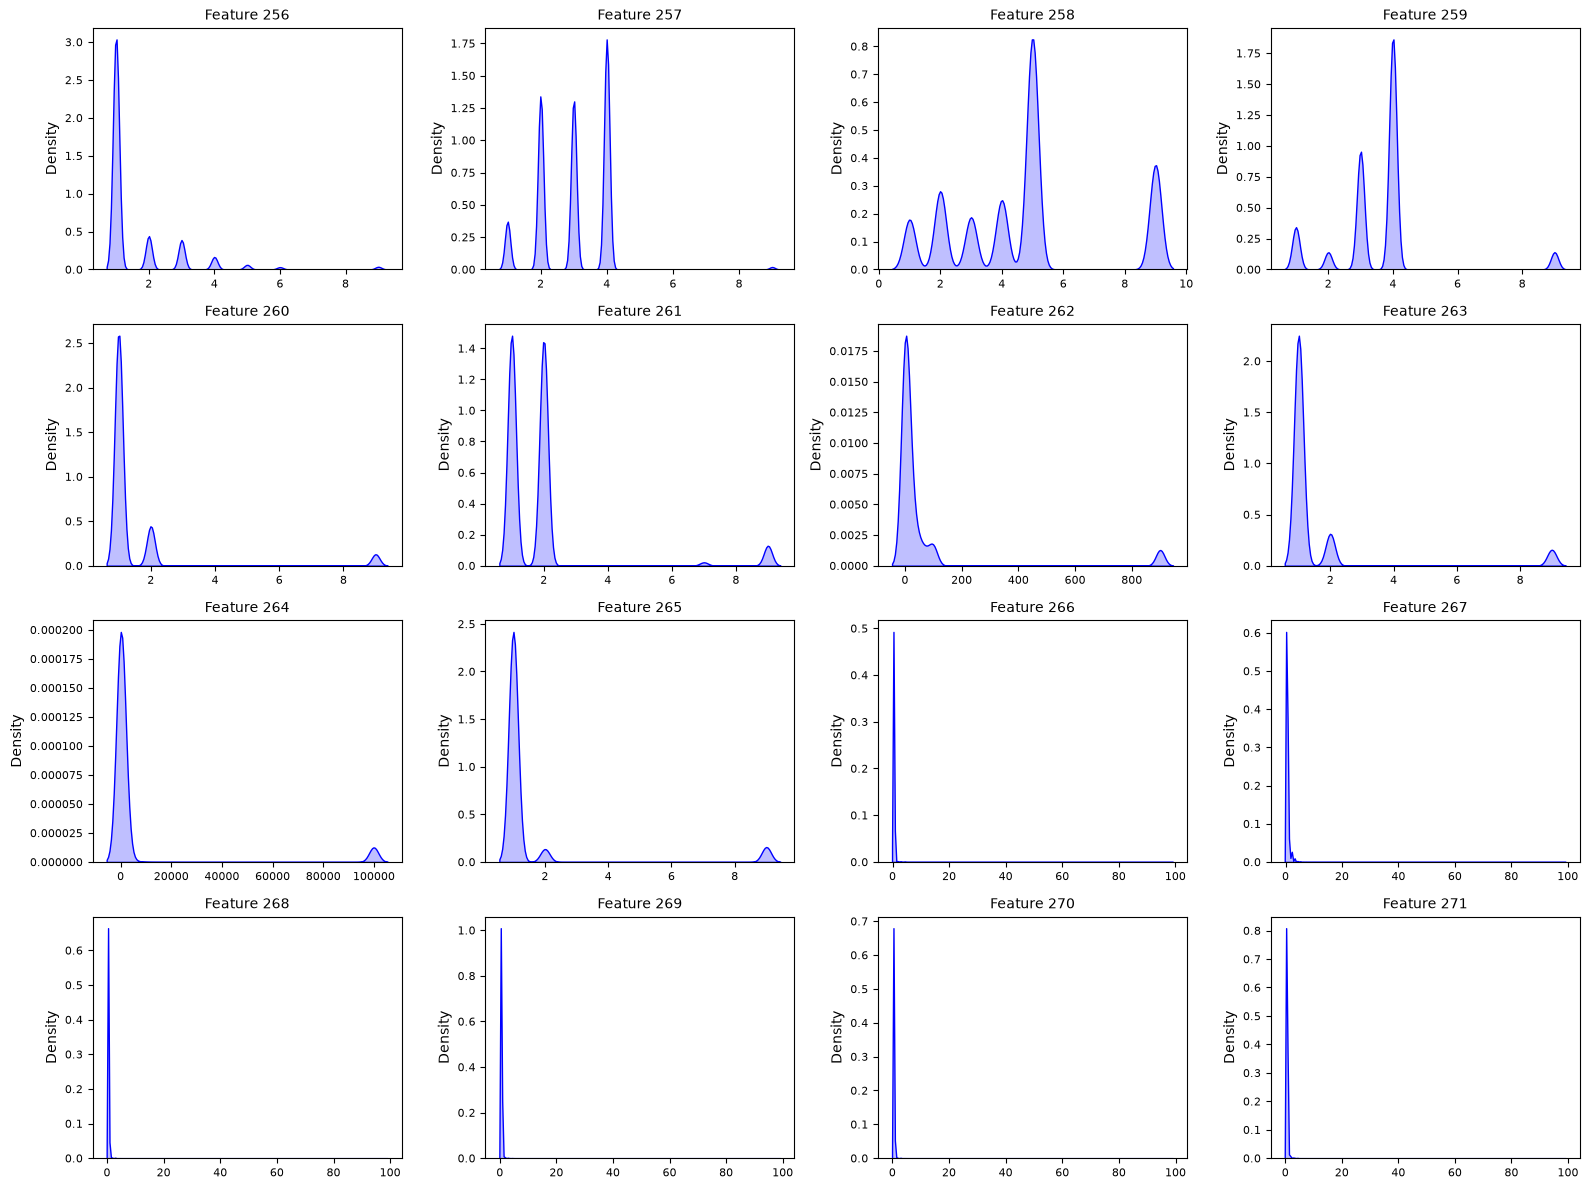

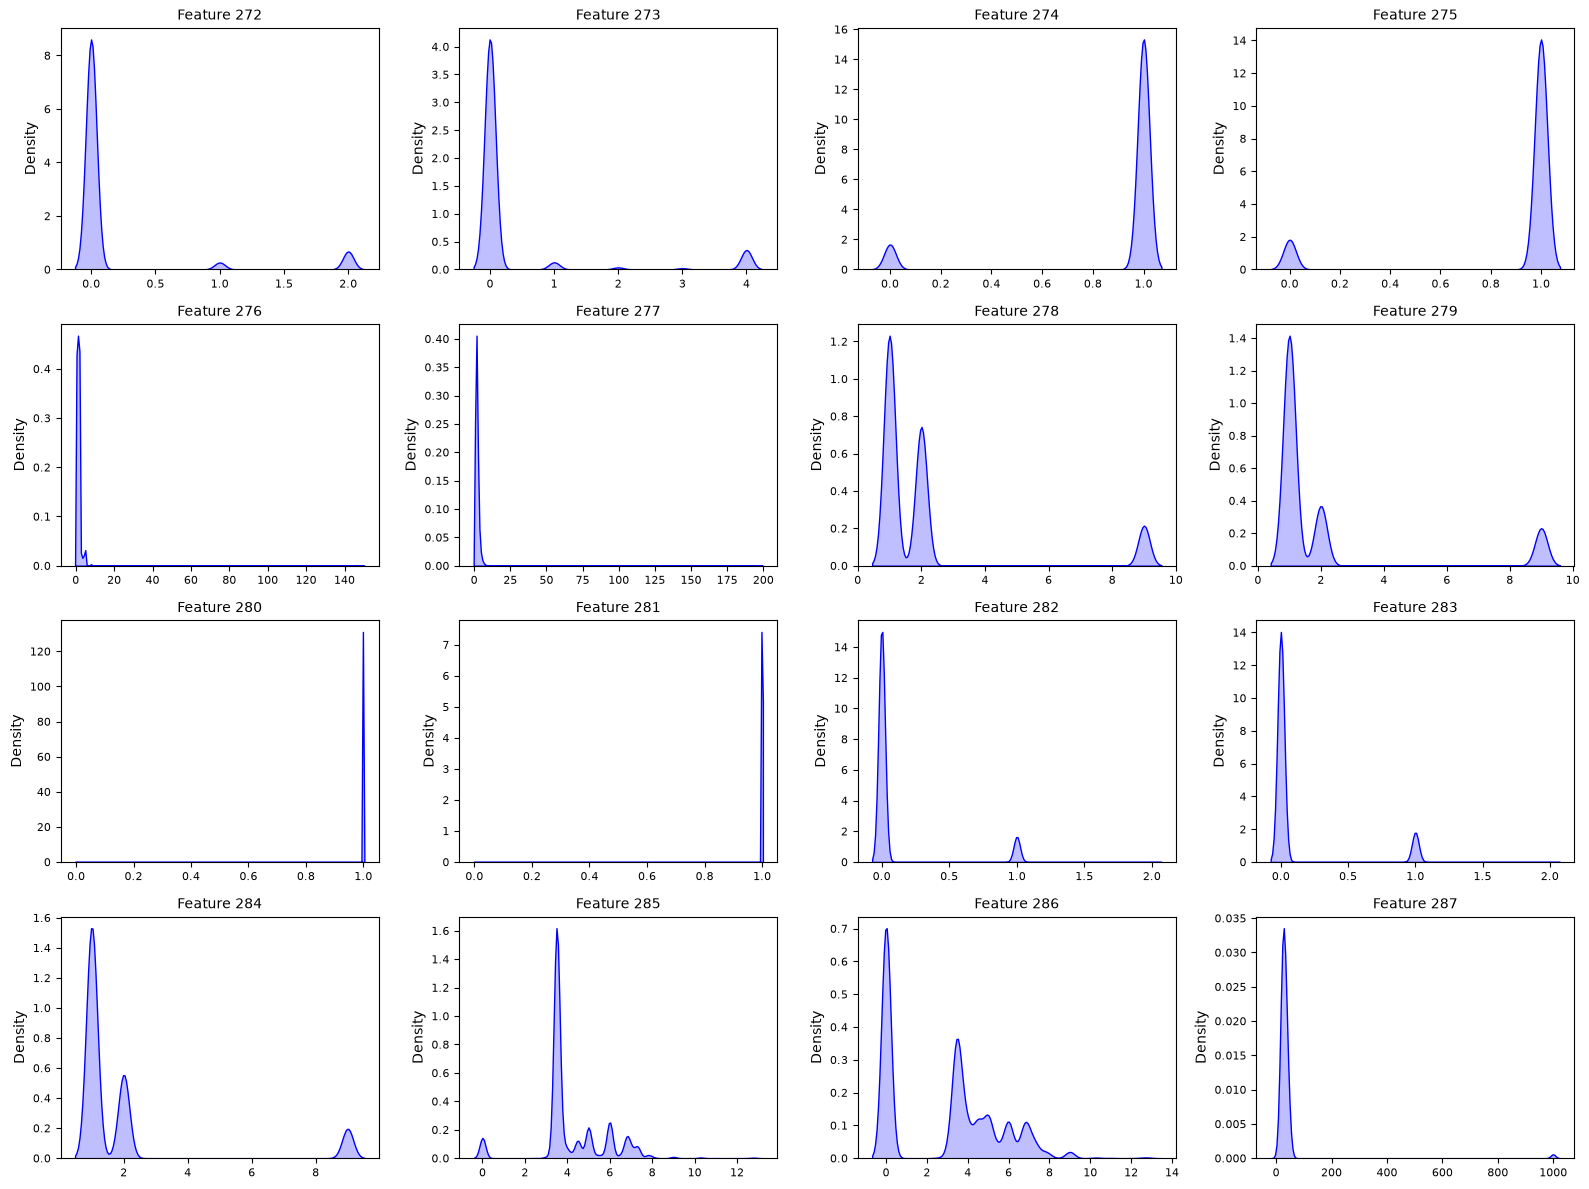

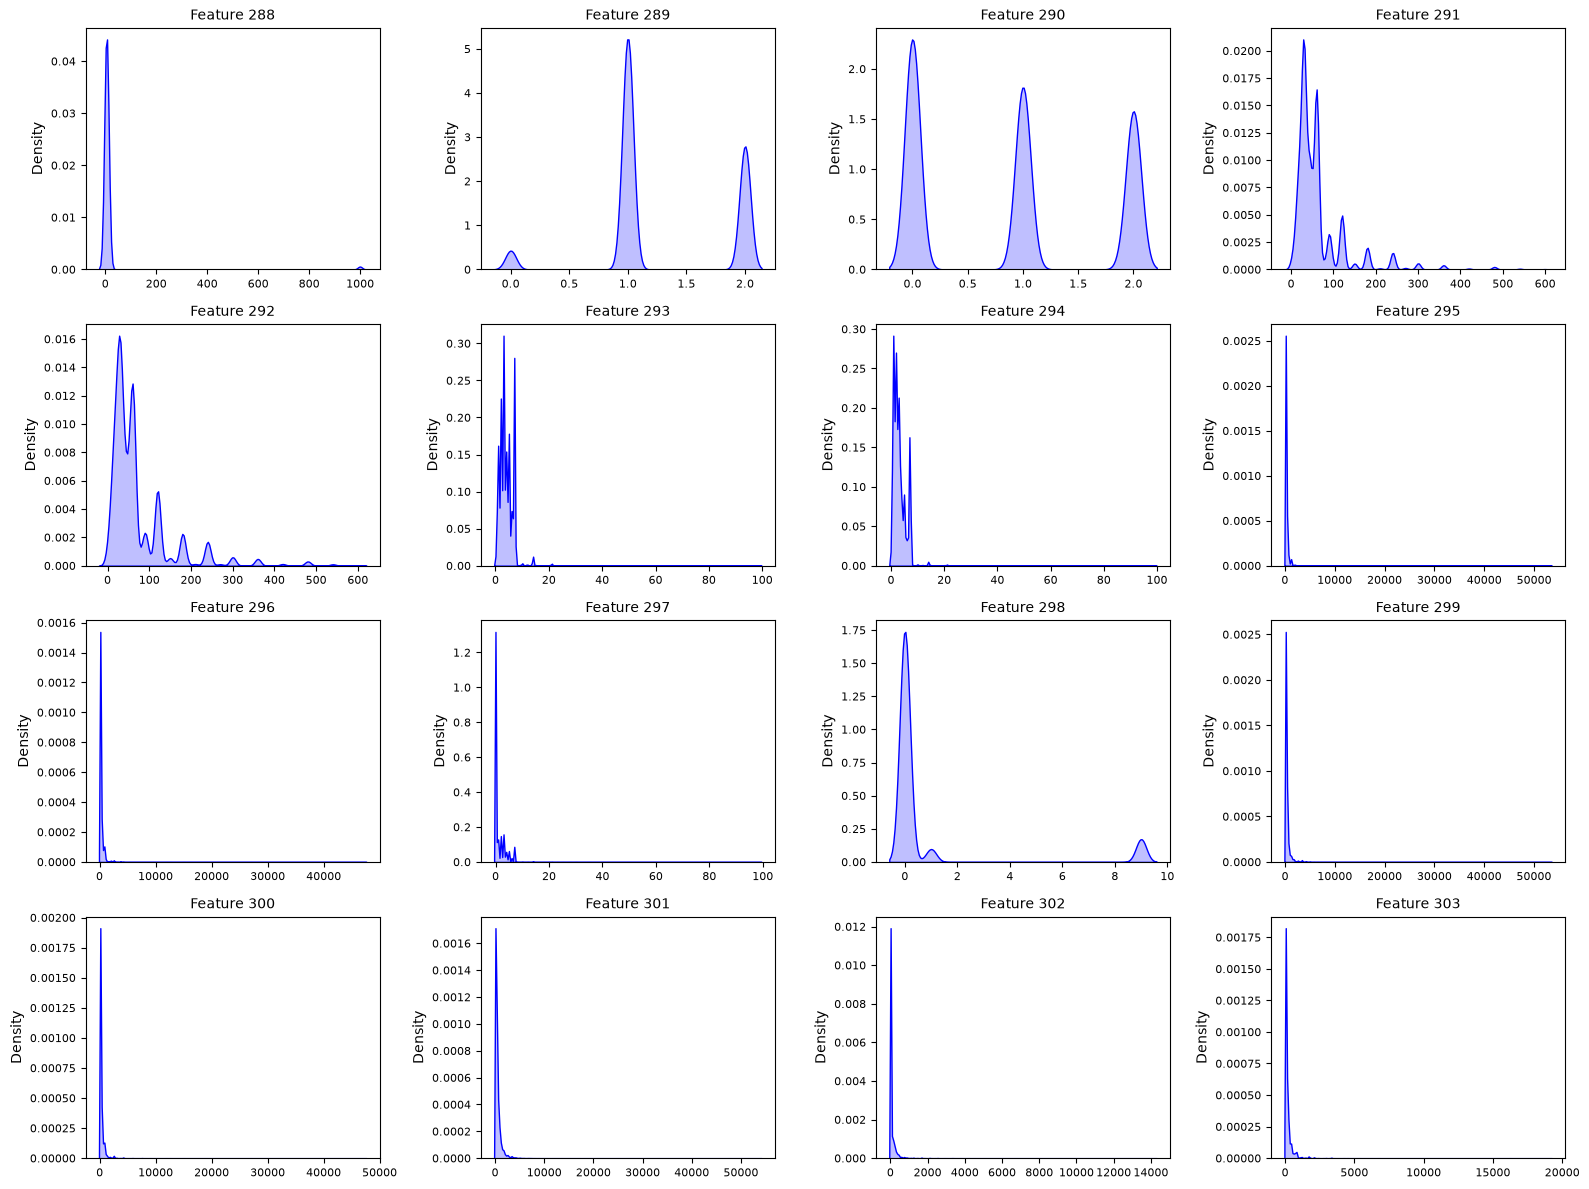

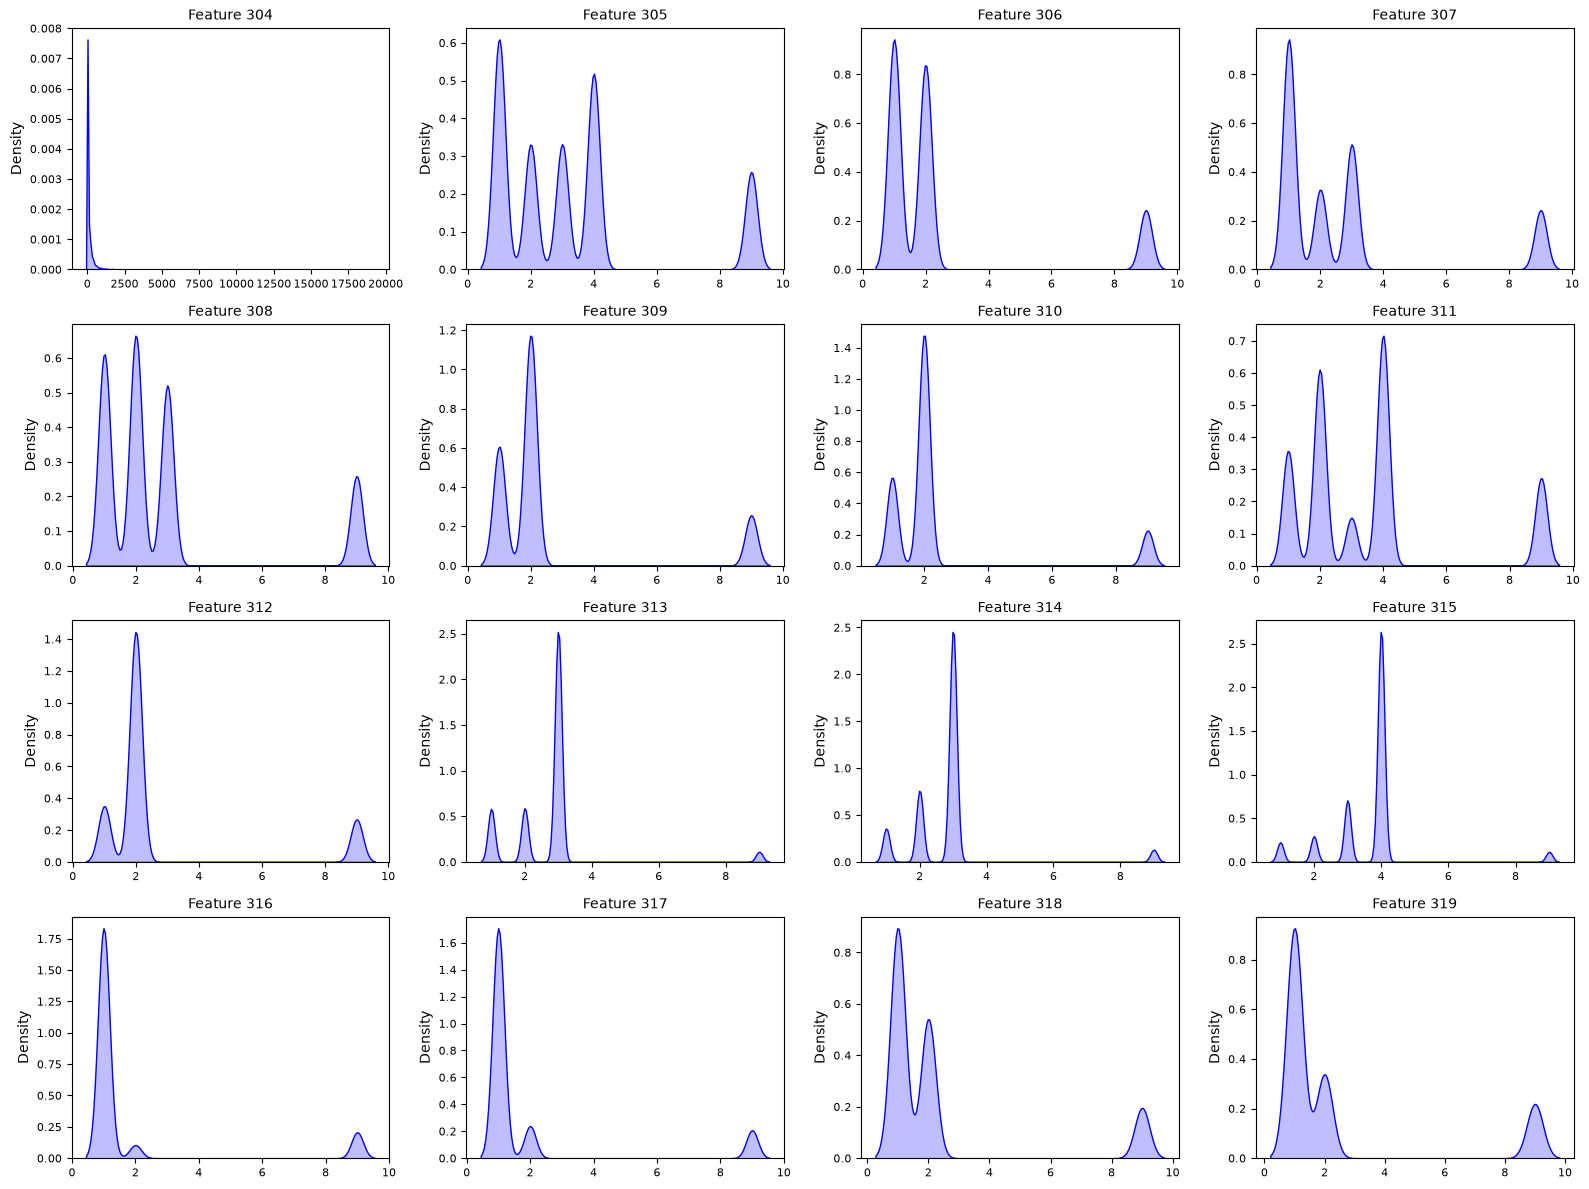

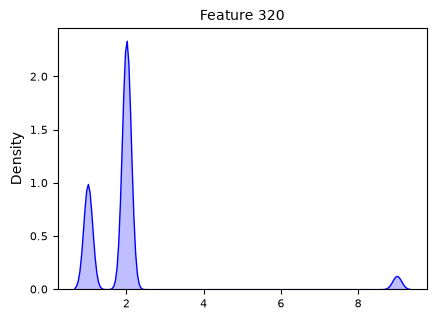

In [ ]:
output_dir = "figures"

N, D = x_train.shape

# Grid configuration (4x4 = 16 subplots per page/image)
PLOTS_PER_PAGE = 16
GRID_COLS = 4
GRID_ROWS = 4

num_pages = math.ceil(D / PLOTS_PER_PAGE)
print(
    f"Generating density plots for {D} features across {num_pages} page(s)..."
)

for page in range(num_pages):
    start_idx = page * PLOTS_PER_PAGE
    end_idx = min((page + 1) * PLOTS_PER_PAGE, D)
    current_features = end_idx - start_idx

    fig, axes = plt.subplots(GRID_ROWS, GRID_COLS, figsize=(16, 12))
    axes = axes.flatten()  # Flatten 2D grid array into 1D for easy indexing

    for i, feat_idx in enumerate(range(start_idx, end_idx)):
        col_data = x_train[:, feat_idx]
        train_valid = col_data[~np.isnan(col_data)]

        ax = axes[i]
        if len(train_valid) > 0:
            sns.kdeplot(
                train_valid, ax=ax, color="blue", fill=True, warn_singular=False
            )
            ax.set_title(f"Feature {feat_idx}", fontsize=10)
        else:
            ax.set_title(f"Feature {feat_idx} (All NaN)", fontsize=10)

        ax.tick_params(axis="both", labelsize=8)

    # Remove blank subplots on the final page if D is not a multiple of 16
    for j in range(current_features, PLOTS_PER_PAGE):
        fig.delaxes(axes[j])

    plt.tight_layout()

    # Save page image
    plot_path = os.path.join(output_dir, f"feature_densities_page_{page + 1}.png")
    plt.savefig(plot_path, dpi=200, bbox_inches="tight")
    print(f"Saved: {plot_path}")

Generating boxplots for 321 features across 17 page(s) (20 features per page)...
Saved: figures/features_boxplot_page_1.png
Saved: figures/features_boxplot_page_2.png
Saved: figures/features_boxplot_page_3.png
Saved: figures/features_boxplot_page_4.png
Saved: figures/features_boxplot_page_5.png
Saved: figures/features_boxplot_page_6.png
Saved: figures/features_boxplot_page_7.png
Saved: figures/features_boxplot_page_8.png
Saved: figures/features_boxplot_page_9.png
Saved: figures/features_boxplot_page_10.png
Saved: figures/features_boxplot_page_11.png
Saved: figures/features_boxplot_page_12.png
Saved: figures/features_boxplot_page_13.png
Saved: figures/features_boxplot_page_14.png
Saved: figures/features_boxplot_page_15.png
Saved: figures/features_boxplot_page_16.png
Saved: figures/features_boxplot_page_17.png


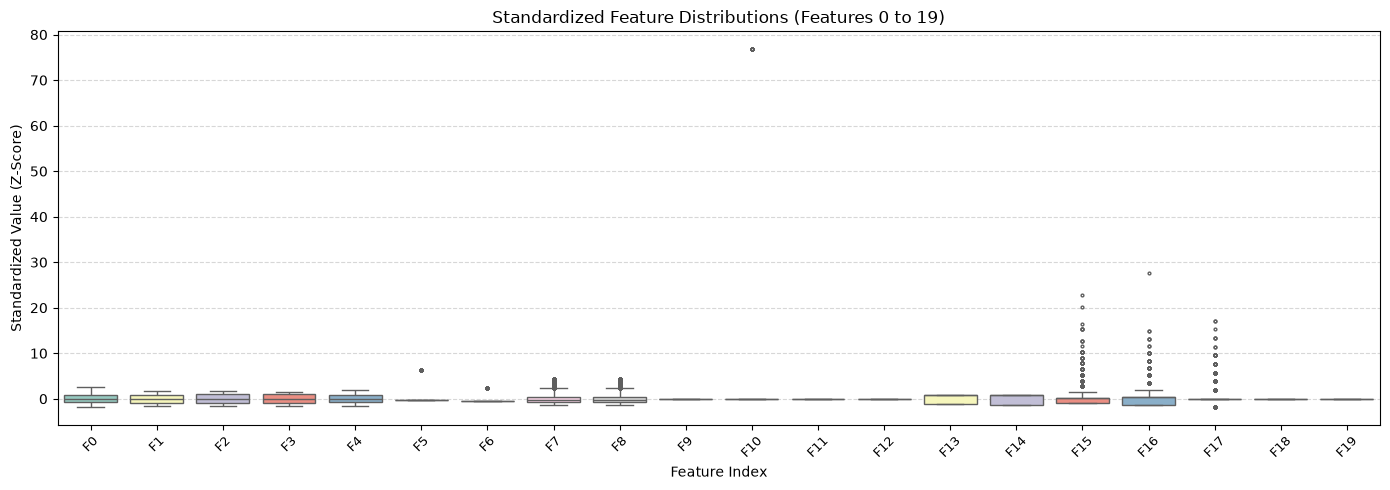

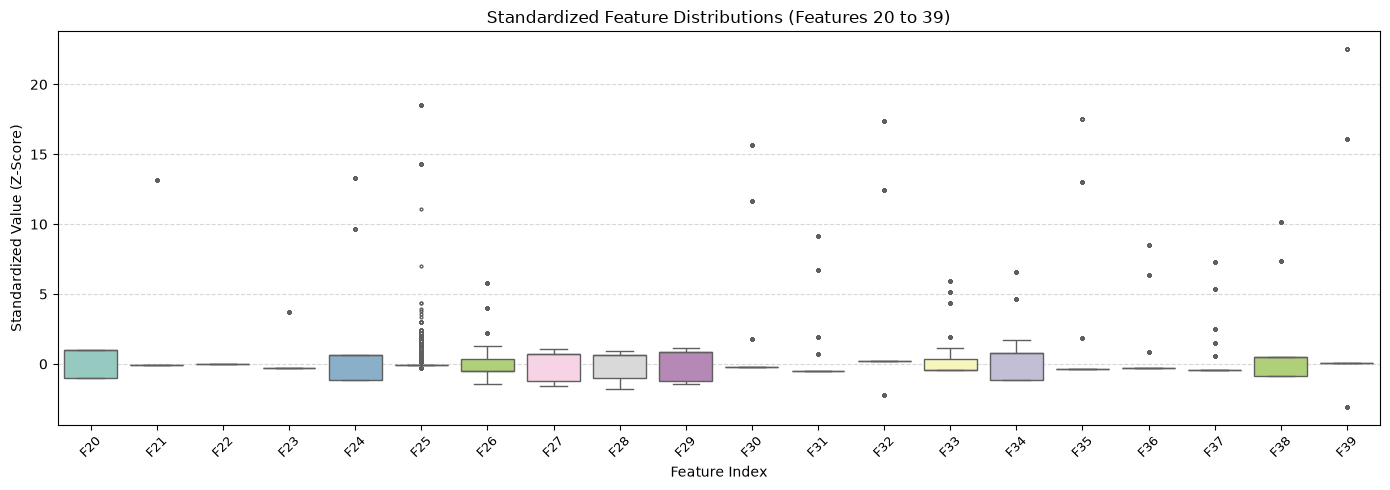

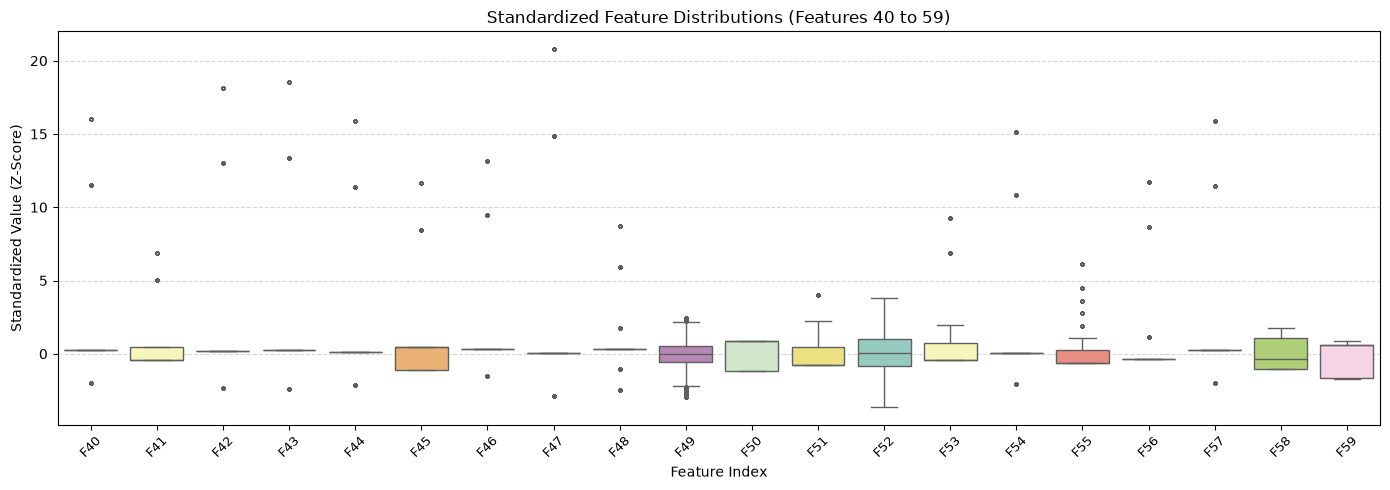

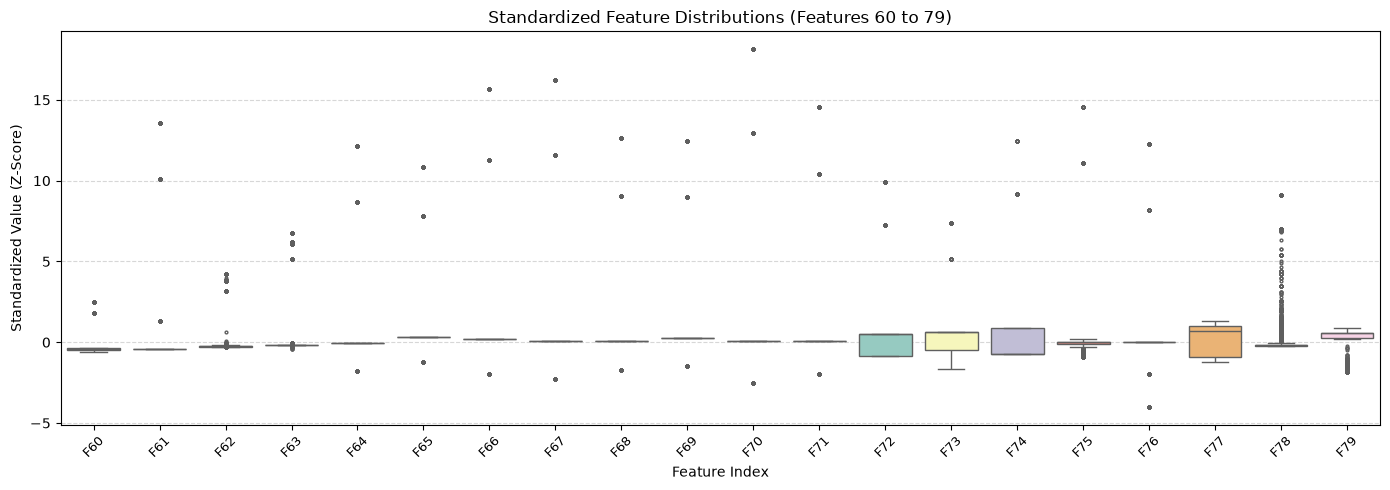

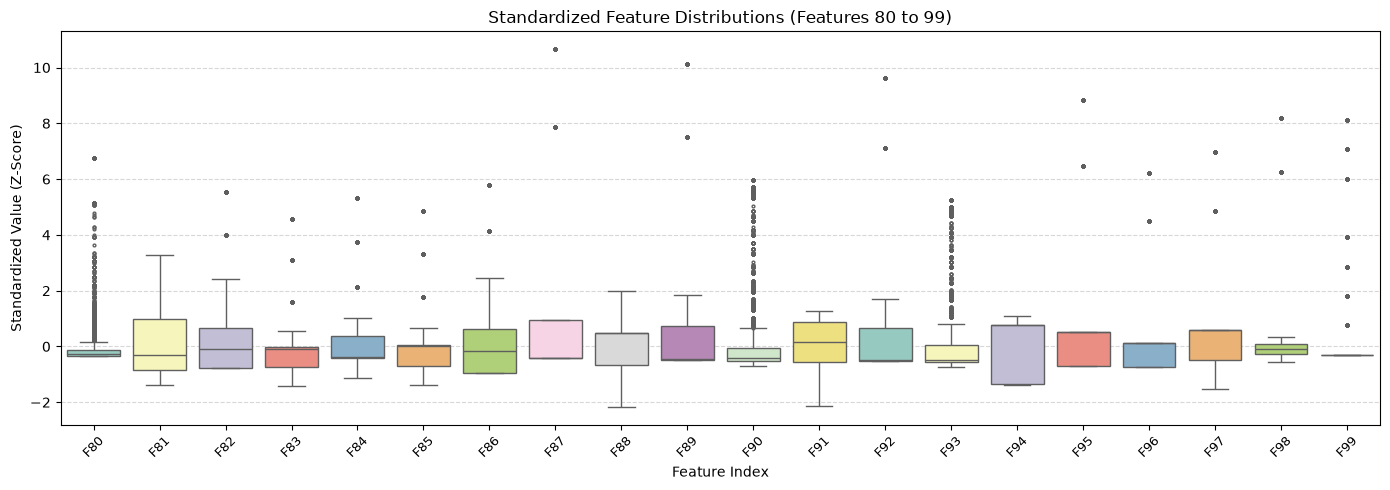

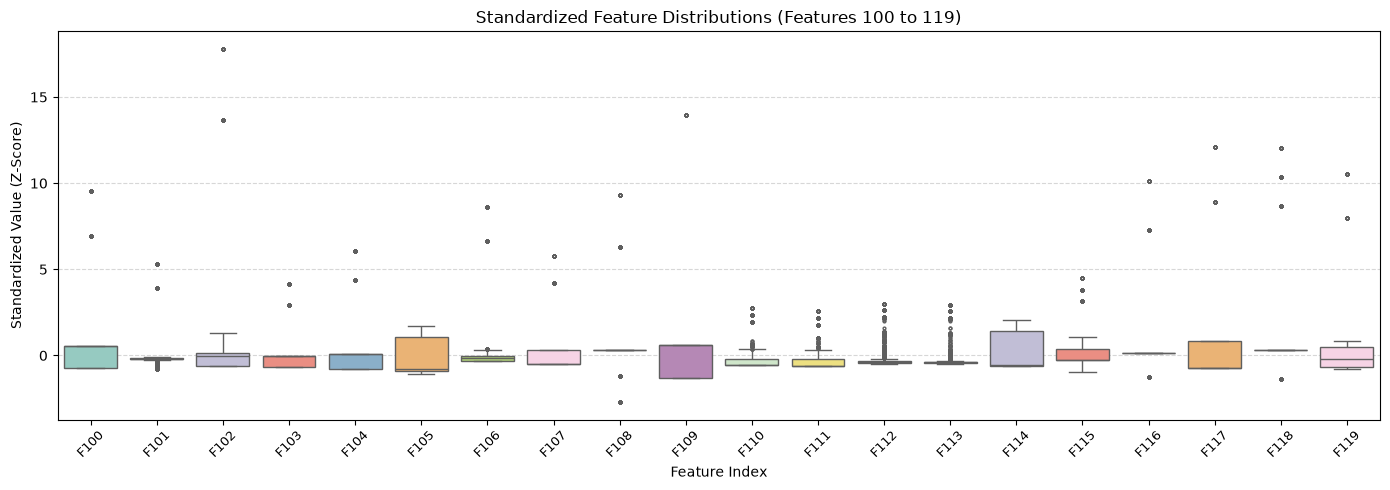

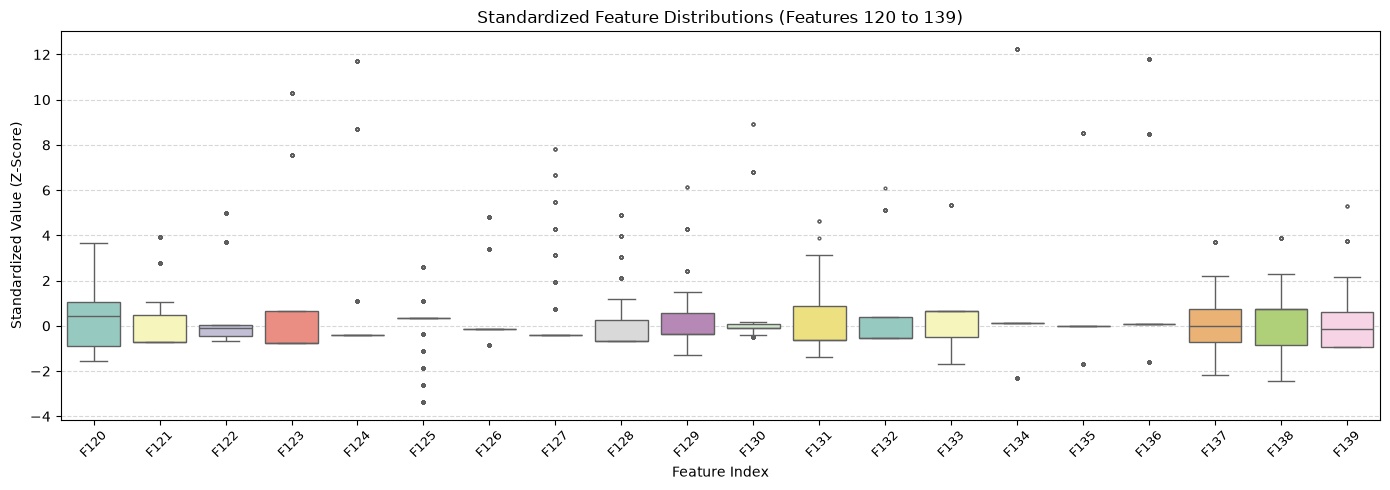

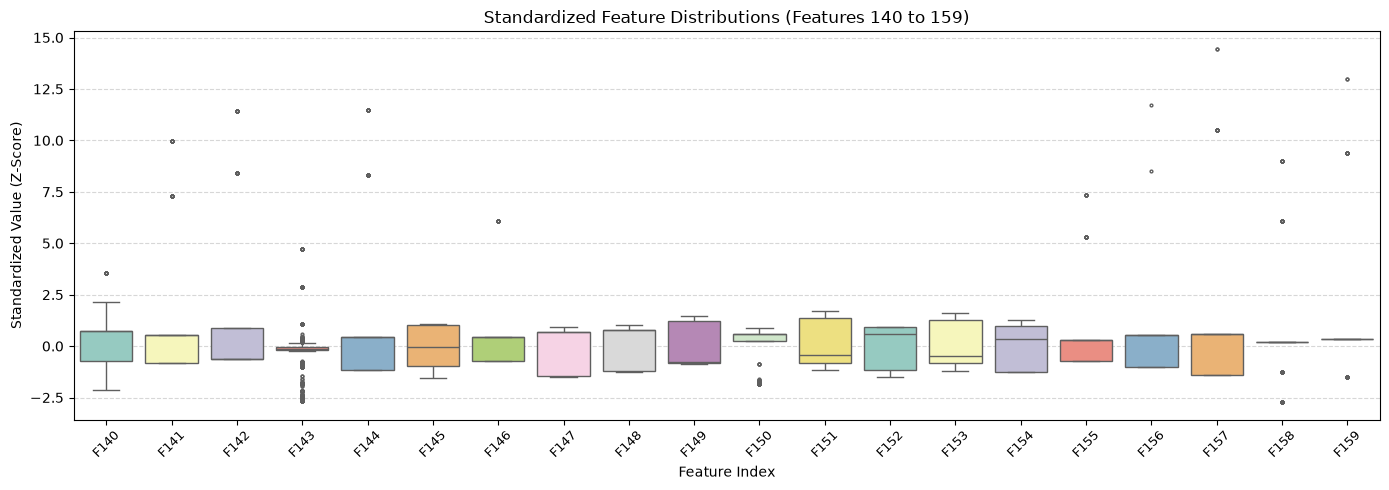

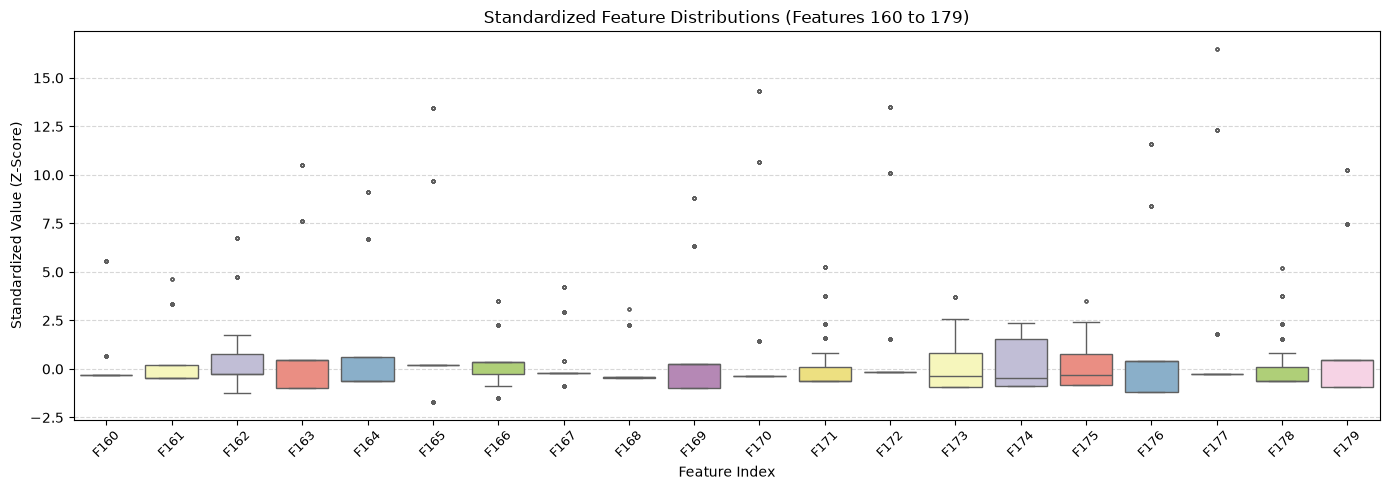

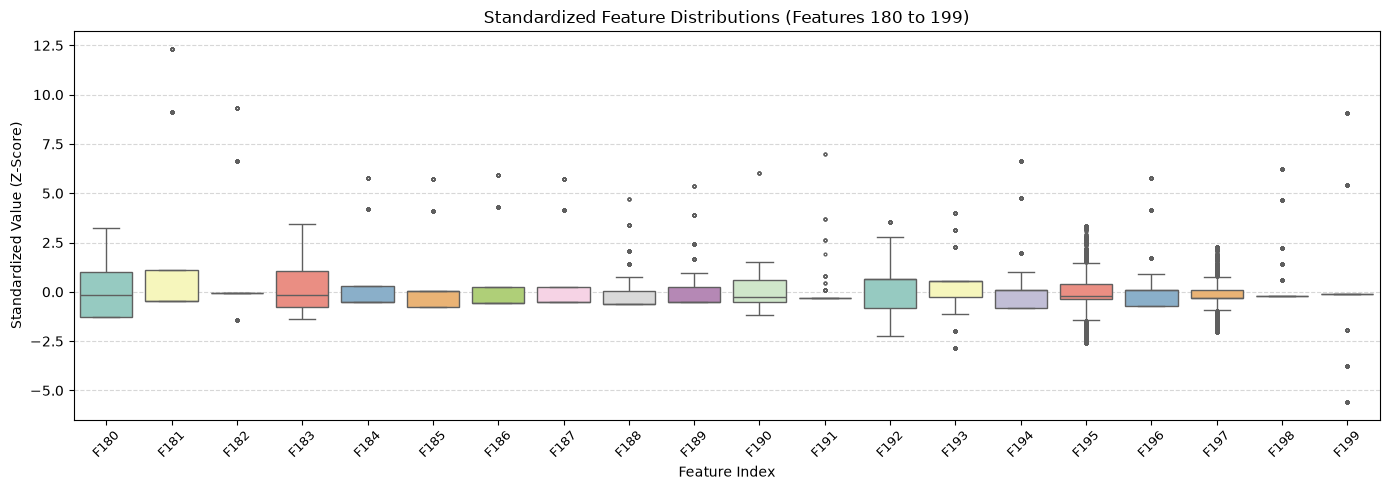

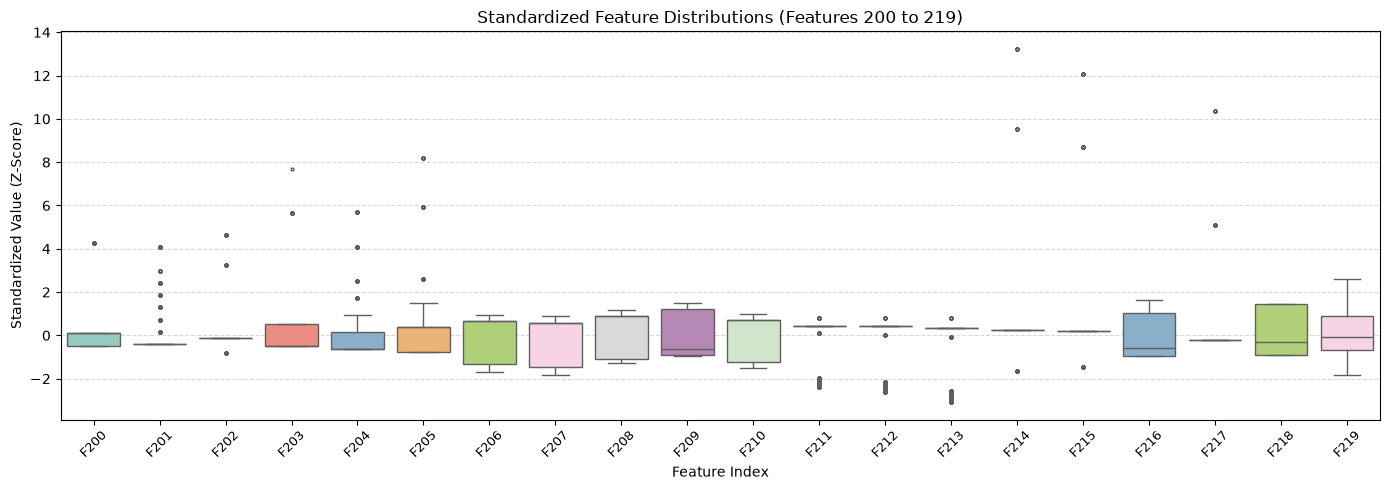

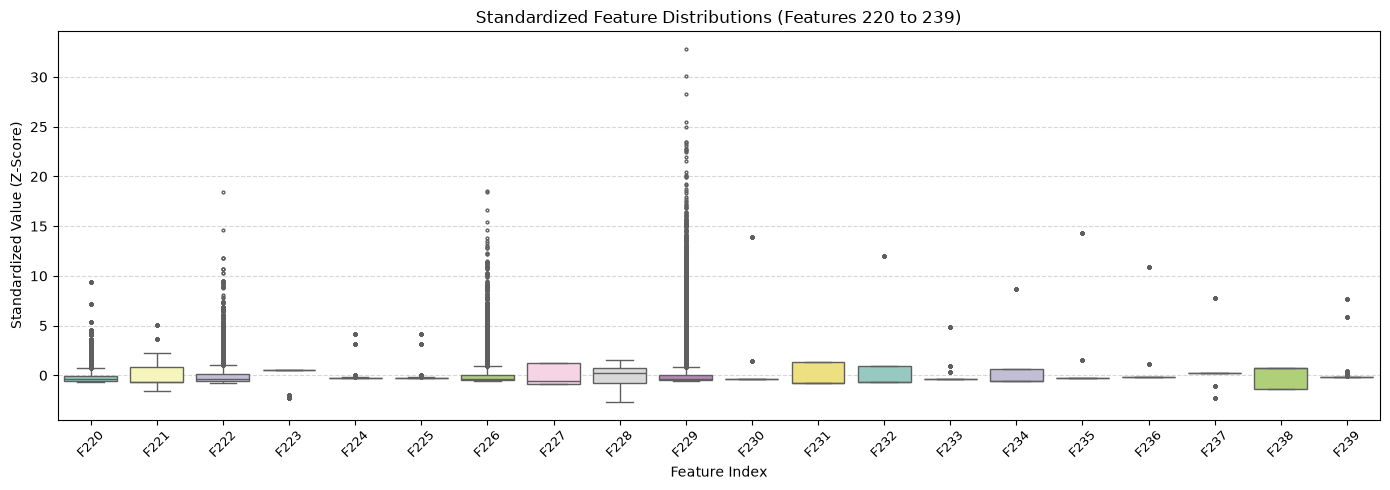

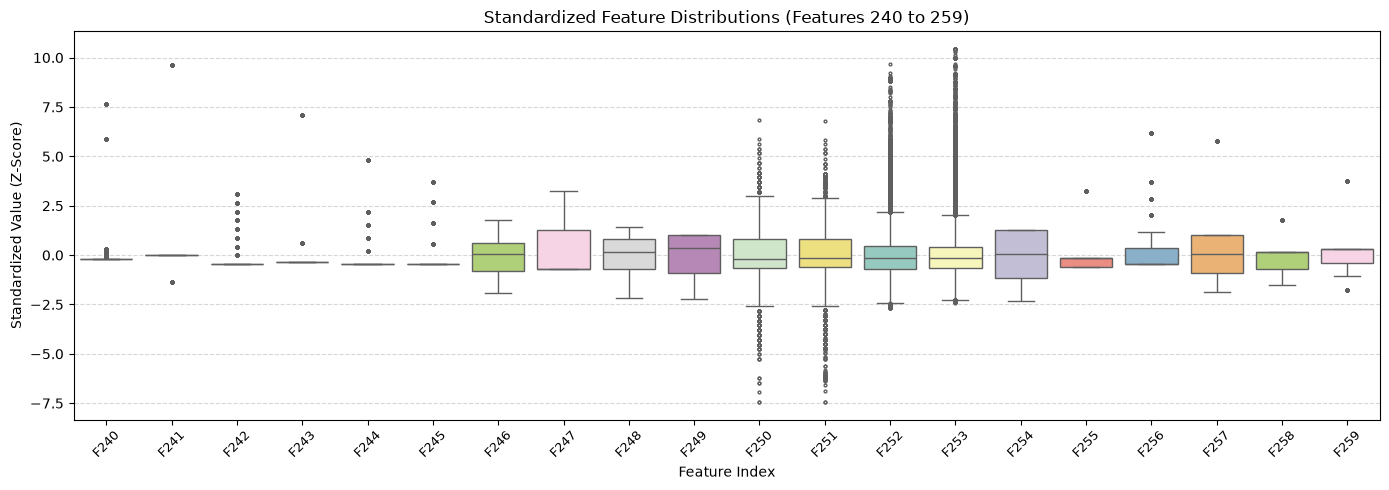

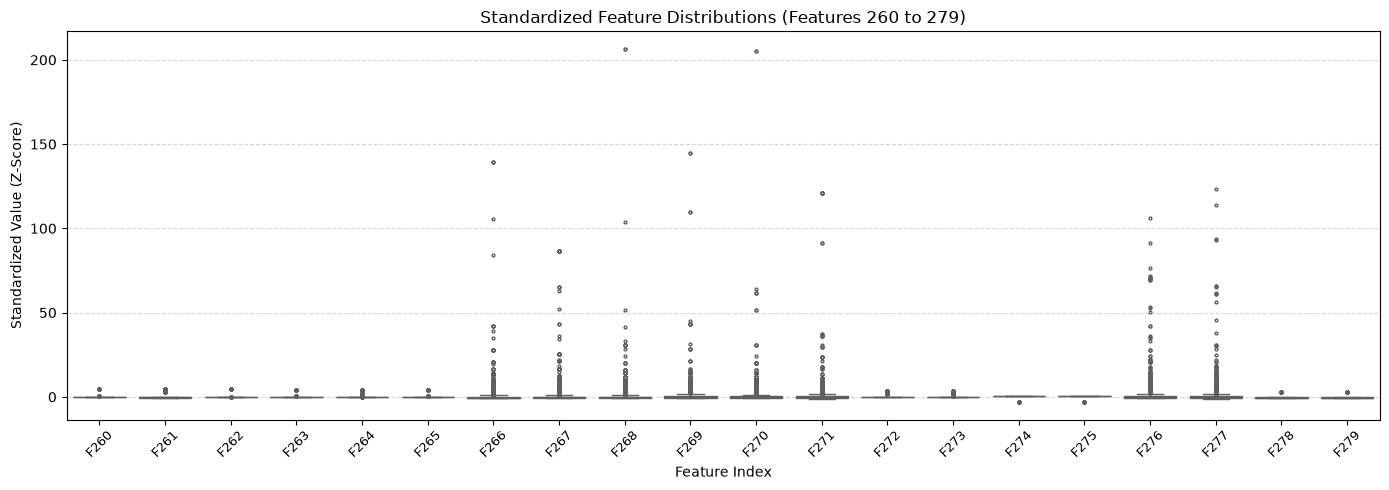

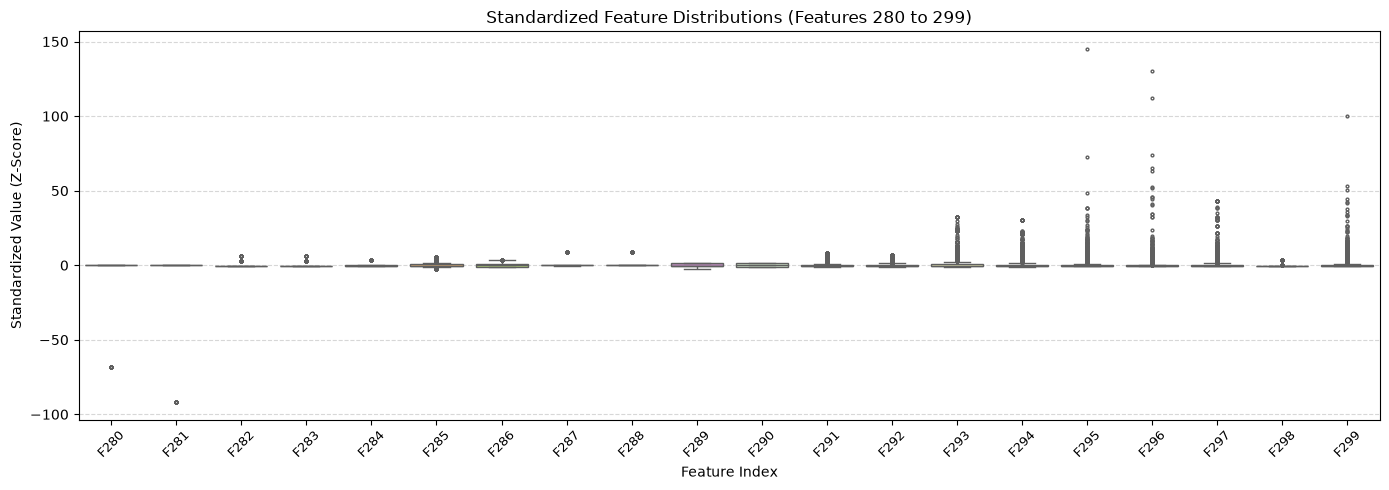

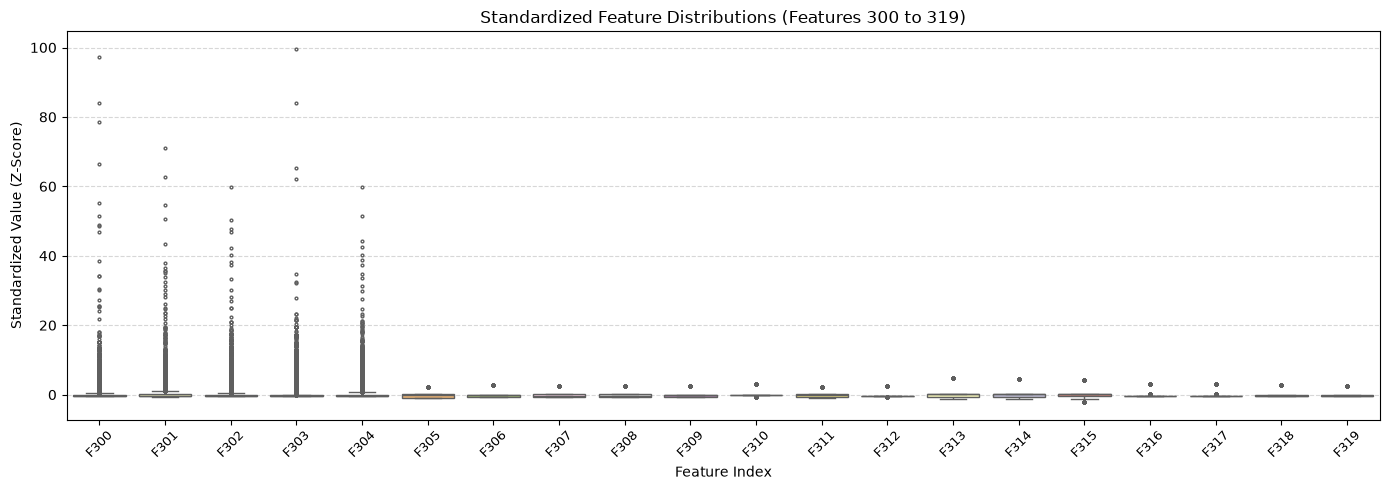

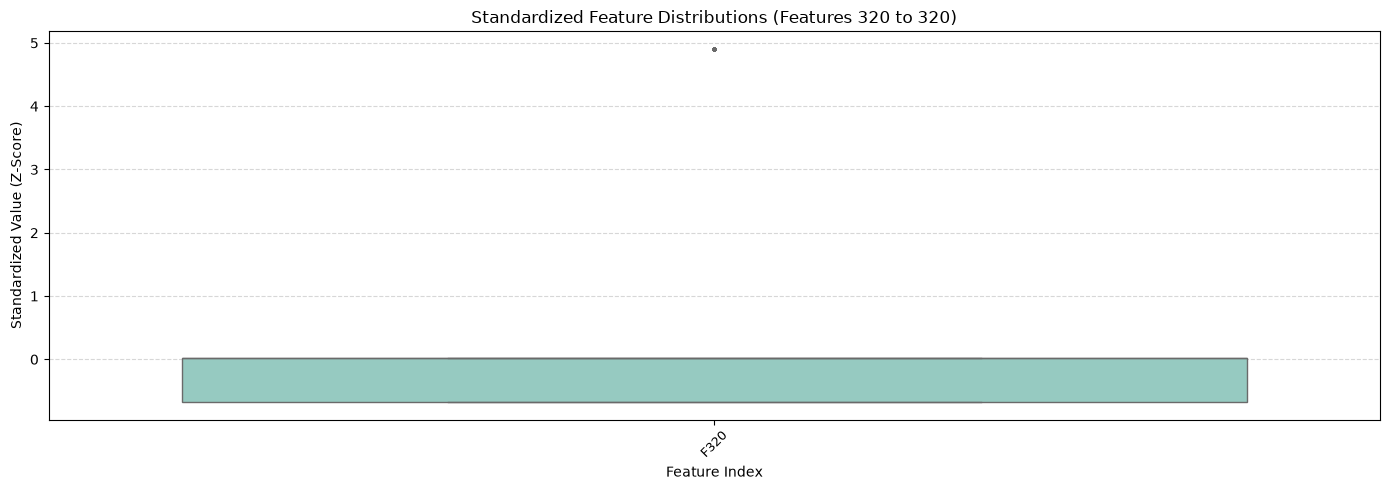

In [5]:
# 1. Standardize features (Z-score normalization)
means = np.nanmean(x_train, axis=0)
stds = np.nanstd(x_train, axis=0)
stds_safe = np.where(stds == 0, 1.0, stds)
x_std = (x_train - means) / stds_safe

# 2. Pagination configuration
FEATURES_PER_PAGE = 20
num_pages = math.ceil(D / FEATURES_PER_PAGE)

print(
    f"Generating boxplots for {D} features across {num_pages} page(s) ({FEATURES_PER_PAGE} features per page)..."
)

for page in range(num_pages):
    start_idx = page * FEATURES_PER_PAGE
    end_idx = min((page + 1) * FEATURES_PER_PAGE, D)

    # Slice the standardized data for the current batch of features
    page_data = x_std[:, start_idx:end_idx]
    feature_labels = [f"F{i}" for i in range(start_idx, end_idx)]

    plt.figure(figsize=(14, 5))
    sns.boxplot(data=page_data, orient="v", palette="Set3", fliersize=2)

    plt.title(
        f"Standardized Feature Distributions (Features {start_idx} to {end_idx - 1})",
        fontsize=12,
    )
    plt.xlabel("Feature Index", fontsize=10)
    plt.ylabel("Standardized Value (Z-Score)", fontsize=10)
    plt.xticks(
        ticks=range(len(feature_labels)),
        labels=feature_labels,
        rotation=45,
        fontsize=9,
    )
    plt.grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()

    # Save page image
    boxplot_path = os.path.join(
        output_dir, f"features_boxplot_page_{page + 1}.png"
    )
    plt.savefig(boxplot_path, dpi=300, bbox_inches="tight")
    print(f"Saved: {boxplot_path}")


## 1.3. Missing Values

In [6]:
# Detect NaN entries across train and test sets
missing_train = np.isnan(x_train)
missing_test = np.isnan(x_test)

train_missing_pct = np.mean(missing_train) * 100
test_missing_pct = np.mean(missing_test) * 100

print(f"Overall Train missing ratio: {train_missing_pct:.2f}%")
print(f"Overall Test missing ratio:  {test_missing_pct:.2f}%\n")

# Per-feature missing value counts
missing_counts = np.sum(missing_train, axis=0)
missing_ratios = missing_counts / len(x_train) * 100

sorted_indices = np.argsort(missing_ratios)[::-1]
print("Top features with missing values (np.nan) in Train:")
for idx in sorted_indices:
    if missing_ratios[idx] > 0:
        print(
            f"  Feature {idx:2d}: {missing_counts[idx]:>7,d} missing ({missing_ratios[idx]:.2f}%)"
        )

Overall Train missing ratio: 44.79%
Overall Test missing ratio:  44.79%

Top features with missing values (np.nan) in Train:
  Feature 14: 328,103 missing (99.99%)
  Feature 11: 328,103 missing (99.99%)
  Feature 191: 327,956 missing (99.95%)
  Feature 147: 327,907 missing (99.93%)
  Feature 148: 327,907 missing (99.93%)
  Feature 152: 327,793 missing (99.90%)
  Feature 154: 327,650 missing (99.85%)
  Feature 153: 327,650 missing (99.85%)
  Feature 151: 327,649 missing (99.85%)
  Feature 150: 327,648 missing (99.85%)
  Feature 149: 327,648 missing (99.85%)
  Feature 146: 327,645 missing (99.85%)
  Feature 156: 327,618 missing (99.84%)
  Feature 190: 327,539 missing (99.82%)
  Feature 155: 327,362 missing (99.76%)
  Feature 145: 327,354 missing (99.76%)
  Feature 130: 327,339 missing (99.76%)
  Feature 22: 327,334 missing (99.76%)
  Feature 168: 327,036 missing (99.67%)
  Feature 131: 326,264 missing (99.43%)
  Feature 135: 325,780 missing (99.28%)
  Feature 134: 325,777 missing (99.28%